# HealthConnect Rwanda: Model Testing, Error Analysis & Refinement
**AnalystLab Africa – Experience Lab, Week 7 · Data Science Track**
Prepared by: Emmanuella Esi Arhin

Week 7 does **not** rebuild Week 6. It takes the Week 6 candidate model and puts it through a structured test programme:
*Week 6 output → Test → Identify issues → Refine → Re-test → Validate → Document → Prepare for Week 8.*

| Section | Content |
|---|---|
| 0 | Week 6 → Week 7 transition |
| 1 | Testing readiness: component, objective, acceptance criteria (fixed **before** testing) |
| 2 | Tests on the Week 6 model *as built* (T1-T12) |
| 3 | Error analysis (false positives / false negatives) and segment performance |
| 4 | Baseline vs candidate: is the improvement meaningful? |
| 5 | Refinement (R1-R4) and re-testing on the locked test set |
| 6 | HC-POD cross-track test: Data Science → ML Engineering interface contract |
| 7 | Cross-track validation of Data Analytics findings that drive modelling decisions |
| 8 | Suitability assessment, limitations, decisions, Week 8 actions |

## 0. Week 6 → Week 7 transition
| # | Item | Answer |
|---|---|---|
| 1 | Main Week 6 output | Data Science package: Data Quality, EDA, Statistical Analysis and Predictive Analytics reports plus the executed notebook `HealthConnect_DataScience_Notebook.ipynb` |
| 2 | Most important Week 6 result | The only classification model in the package: **Task 3, hospital-admission proxy** (target = Emergency visit *and* Severe diagnosis). Best model: gradient boosting, patient-grouped 5-fold CV AUC **0.505** (95% CI 0.479-0.531) vs a 0.50 coin flip |
| 3 | Main issue / limitation carried from Week 6 | (a) The result was judged with cross-validation only: no locked hold-out set, and the decision threshold was tuned on the same predictions that were scored; (b) the F1-optimal threshold flagged ~95% of appointments; (c) features whose reliability Week 6 itself questioned (facility, department, BMI) were still in the model; (d) there is no admissions table and no attendance/no-show field |
| 4 | Component requiring testing | The Week 6 candidate classifier and its preprocessing pipeline (`ColumnTransformer` + `HistGradientBoostingClassifier`) |
| 5 | Relevant tracks | Data Science (owner) · Data Analytics (validated findings that drive feature decisions) · ML Engineering (pipeline interface) · Project Management (issue log, readiness) |
| 6 | What I will test | Reproducibility, independent hold-out performance, stability, signal vs chance (permutation test), over-fitting, time-based validity, calibration, errors and segments, feature reliability, leakage, target definition, and a positive-control check that the test harness *can* detect signal |
| 7 | What I expect to improve / validate | Replace the optimistic CV-only evidence with a locked-test verdict; remove unreliable features; replace the degenerate threshold with a flag-rate budget; add a release gate; deliver a tested model-input contract to ML Engineering |

In [3]:
import os, re, json, time, warnings, platform, hashlib, textwrap, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
import sklearn
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix, matthews_corrcoef,
                             precision_recall_curve, roc_curve)
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid", context="notebook")
PAL = {"teal":"#0F766E","blue":"#1D4ED8","amber":"#D97706","red":"#B91C1C","grey":"#6B7280","green":"#15803D","purple":"#7C3AED"}
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":150, "axes.titleweight":"bold", "axes.titlesize":12, "axes.labelsize":10})

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed" / "HC_Analytical_Dataset.csv").exists())
PROC = ROOT / "data" / "processed"; RAW = ROOT / "data" / "raw"
print("Using:", PROC)
PROC = ROOT / "data" / "processed"
RAW  = ROOT / "data" / "raw"
FIG, OUT = ROOT / "week7" / "figures_w7", ROOT / "week7" / "outputs_w7"
FIG.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
W7 = {}            # key results exported for the report
FIGS = []
def savefig(fig, name, title, interp):
    fig.suptitle(title, fontsize=13, fontweight="bold", y=0.995)
    fig.text(0.01, -0.02, "\n".join(textwrap.wrap("Interpretation: " + interp, 150)), ha="left", va="top", fontsize=8.5, style="italic", color="#374151")
    fig.tight_layout(rect=[0,0,1,0.97]); path = FIG/f"{name}.png"; fig.savefig(path, bbox_inches="tight"); FIGS.append(dict(file=str(path), title=title, interpretation=interp)); plt.show()
print("sklearn", sklearn.__version__, "| python", platform.python_version())

Using: d:\Analyst_lab\Healthcare_Predictive_Analytics_and_Population_Health_Intelligence\data\processed
sklearn 1.9.0 | python 3.14.6


### 0.1 Load the Week 6 integrated dataset (derived file, raw files untouched)
Week 7 reads `HC_Analytical_Dataset.csv`, written by the Week 6 notebook. The original project resources are never modified. The first tests verify that the file is the same dataset Week 6 analysed.

In [4]:
df = pd.read_csv(PROC/"HC_Analytical_Dataset.csv", keep_default_na=False, na_values=[""], parse_dates=["Date"])
df["future_dated"] = df["future_dated"].astype(bool)
AS_OF = pd.Timestamp("2026-10-24")
TARGET = "HighAcuityEmergency"
NUM = ["Age","BMI_clean","PriorVisits","MonthNum","WeekdayNum","DoctorYears","DeptWorkloadIndex","HasChronic"]
CAT = ["Gender","ChronicCondition","Diagnosis","DepartmentName","ProvinceName","FacilityID"]
FEATS = NUM + CAT
X, y, groups = df[FEATS].copy(), df[TARGET].values.astype(int), df.PatientID.values

integrity = pd.DataFrame([
  ("Row count = 5,000 appointments (Week 6)", len(df) == 5000),
  ("AppointmentID unique", df.AppointmentID.is_unique),
  ("Target positives = 544 (10.88%, Week 6)", int(y.sum()) == 544),
  ("Target = Emergency AND Severe (rebuilt from raw columns)", bool((((df.VisitType=="Emergency") & (df.Severity=="Severe")).astype(int).values == y).all())),
  ("No missing values in the target", not pd.isna(df[TARGET]).any()),
  ("Feature columns all present", all(c in df.columns for c in FEATS)),
  ("Categorical labels in canonical Title case (cleaning applied)", bool((df.Gender.isin(["Male","Female"])).all())),
  ("PriorVisits equals number of earlier visits by the same patient", None),
], columns=["Integrity check","Pass"])
# PriorVisits timing audit: recompute from dates (leakage check: only strictly earlier visits may be counted)
_s = df.sort_values(["PatientID","Date","AppointmentID"]); _pv = _s.groupby("PatientID").cumcount()
integrity.loc[integrity["Integrity check"].str.startswith("PriorVisits"), "Pass"] = bool((_pv.reindex(df.index).values == df.PriorVisits.values).all())
integrity["Pass"] = integrity["Pass"].map({True:"PASS", False:"FAIL"})
W7["integrity"] = integrity.to_dict("records")
print("Dataset:", df.shape); integrity

Dataset: (5000, 70)


,Integrity check,Pass
0,"Row count = 5,000 appointments (Week 6)",PASS
1,AppointmentID unique,PASS
2,"Target positives = 544 (10.88%, Week 6)",PASS
3,Target = Emergency AND Severe (rebuilt from ra...,PASS
4,No missing values in the target,PASS
5,Feature columns all present,PASS
6,Categorical labels in canonical Title case (cl...,PASS
7,PriorVisits equals number of earlier visits by...,PASS


## 1. Testing readiness
### 1.1 Component, purpose and requirement
| Field | Content |
|---|---|
| **Component tested** | Week 6 candidate classifier: preprocessing (median impute + scale numeric, one-hot categorical) + `HistGradientBoostingClassifier(max_depth=3, learning_rate=0.04, max_iter=120, l2_regularization=5)` |
| **Intended purpose** | Estimate the probability that an appointment needs admission (Week 6 brief, Task 3; proxy = Emergency visit with Severe diagnosis) so that beds and staff can be planned |
| **Requirement it should satisfy** | Data Science brief, Predictive Analytics Task 3, and the HealthConnect question: *can data and AI help the clinic plan and support patients better?* A model that cannot separate high-need from low-need appointments cannot support planning |
| **Connected tracks** | Data Analytics (finding validity), ML Engineering (pipeline hand-off), Project Management (issues, readiness) |

### 1.2 Testing objective
Determine whether the Week 6 candidate (a) reproduces, (b) performs on data it has never influenced, (c) beats chance and the Week 5/6 baseline by a **meaningful** margin, (d) behaves consistently across time and patient segments, and (e) can be handed to ML Engineering safely. Then refine and re-test.

### 1.3 Acceptance criteria (fixed before any test was run)
A model is called **suitable for the HealthConnect use case** only if it passes the *mandatory* criteria (M). The others (S) describe quality that a suitable model should also meet.

In [5]:
CRITERIA = pd.DataFrame([
 ("AC1","S","Reproducibility","Re-running the Week 6 protocol reproduces the reported AUC (0.505) within +/-0.005"),
 ("AC2","M","Discrimination on locked test set","Hold-out AUC >= 0.60 and the lower 95% bootstrap bound > 0.50"),
 ("AC3","M","Operational value","Precision in the top-20% highest-scored appointments (lift) >= 1.30 x prevalence, lower bound of lift > 1.0"),
 ("AC4","S","Stability","At least 90% of 10 repeated grouped-CV runs have AUC > 0.55"),
 ("AC5","M","Signal vs chance","Label-permutation test p < 0.05"),
 ("AC6","S","Calibration","Calibration slope within 0.8-1.2 and Brier score better than the prevalence-only forecast"),
 ("AC7","S","Over-fitting","Train-minus-validation AUC gap <= 0.05"),
 ("AC8","S","Time-based validity","AUC >= 0.55 when trained on Jan-Aug and tested on Sep-Dec"),
 ("AC9","M","Meaningful improvement over baseline","Paired-bootstrap delta-AUC vs baseline >= 0.05 with the 95% lower bound > 0"),
 ("AC10","S","Segment parity","Recall and flag-rate gap between sex, age-band and province groups <= 10 percentage points (groups with n >= 100)"),
], columns=["ID","Type","Criterion","Pass rule"])
W7["criteria"] = CRITERIA.to_dict("records"); CRITERIA

,ID,Type,Criterion,Pass rule
0,AC1,S,Reproducibility,Re-running the Week 6 protocol reproduces the ...
1,AC2,M,Discrimination on locked test set,Hold-out AUC >= 0.60 and the lower 95% bootstr...
2,AC3,M,Operational value,Precision in the top-20% highest-scored appoin...
3,AC4,S,Stability,At least 90% of 10 repeated grouped-CV runs ha...
4,AC5,M,Signal vs chance,Label-permutation test p < 0.05
5,AC6,S,Calibration,Calibration slope within 0.8-1.2 and Brier sco...
6,AC7,S,Over-fitting,Train-minus-validation AUC gap <= 0.05
7,AC8,S,Time-based validity,AUC >= 0.55 when trained on Jan-Aug and tested...
8,AC9,M,Meaningful improvement over baseline,Paired-bootstrap delta-AUC vs baseline >= 0.05...
9,AC10,S,Segment parity,"Recall and flag-rate gap between sex, age-band..."


### 1.4 Test plan
| ID | Test / scenario | Expected result if the Week 6 model is sound |
|---|---|---|
| T1 | Reproduce Week 6 CV protocol | AUC = 0.505 (AC1) |
| T2 | Locked 20% patient-grouped hold-out, threshold chosen by nested CV on training data only | AUC clearly above 0.5 (AC2) |
| T3 | 10 x repeated grouped 5-fold CV | Stable AUC well above 0.5 (AC4) |
| T4 | Label-permutation test (100 shuffles) | Observed AUC beyond the null distribution (AC5) |
| T5 | Over-fitting: train vs validation AUC | Small gap (AC7) |
| T6 | Time-based split (train Jan-Aug, test Sep-Dec) | AUC holds in the future (AC8) |
| T7 | Calibration | Probabilities match observed rates (AC6) |
| T8 | Operating-point test (F1-threshold vs flag-rate budget) | Threshold flags a sensible share of appointments |
| T9 | Error analysis: FP vs TN, FN vs TP | Errors show explainable, fixable patterns |
| T10 | Segment performance and fairness | Similar performance across groups (AC10) |
| T11 | Feature review: reliability audit, drop-group ablation, leakage audit | Every feature carries signal and is trustworthy |
| T12 | Target-definition scan + positive control | Harness detects real signal; other targets show whether *any* signal exists |

## 2. Tests on the Week 6 model *as built*
Shared helpers first. The model factories below are copied unchanged from the Week 6 notebook (same hyper-parameters, same seed).

In [6]:
def make_prep(num, cat):
    return ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False), cat)])
def make_pipe(est, num=NUM, cat=CAT): return Pipeline([("prep", make_prep(num, cat)), ("m", est)])
def gb_w6():  return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.04, max_iter=120, l2_regularization=5, random_state=SEED)
def lr_w6():  return LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced")
def dummy():  return DummyClassifier(strategy="prior")
CAND = lambda: make_pipe(gb_w6())          # Week 6 candidate, unchanged
LOGR = lambda: make_pipe(lr_w6())          # Week 6 first-pass classifier
BASE = lambda: make_pipe(dummy())          # prevalence baseline

def cv_split(seed, n=5): return StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=seed)
def oof_scores(factory, X, y, g, seed=SEED, cols=None):
    Xc = X if cols is None else X[cols]
    return cross_val_predict(factory(), Xc, y, groups=g, cv=cv_split(seed), method="predict_proba")[:, 1]

def f1_threshold(y, s):
    pr, rc, th = precision_recall_curve(y, s); f1 = 2*pr*rc/np.maximum(pr+rc, 1e-12)
    return float(th[np.nanargmax(f1[:-1])]) if len(th) else float(np.min(s))

def op_metrics(y, s, thr):
    yh = (s >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0,1]).ravel(); prev = y.mean()
    prec = tp/max(tp+fp,1); rec = tp/max(tp+fn,1); spec = tn/max(tn+fp,1)
    return dict(Threshold=thr, FlagRate=yh.mean(), Precision=prec, Recall=rec, Specificity=spec, F1=2*tp/max(2*tp+fp+fn,1), BalancedAcc=(rec+spec)/2,
                MCC=matthews_corrcoef(y, yh) if yh.min()!=yh.max() else 0.0, Lift=prec/prev if prev>0 else np.nan, TP=int(tp), FP=int(fp), FN=int(fn), TN=int(tn))

def rank_threshold(s_ref, flag_rate):          # score cut-off that flags the top `flag_rate` of a reference set
    return float(np.quantile(s_ref, 1-flag_rate))

def boot(fn, y, s, B=1000, seed=SEED):
    r = np.random.default_rng(seed); n = len(y); v = []
    for _ in range(B):
        i = r.integers(0, n, n)
        if y[i].min() == y[i].max(): continue
        v.append(fn(y[i], s[i]))
    v = np.array(v); return float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))
def lift_at(thr):
    return lambda yy, ss: ((ss >= thr) & (yy == 1)).sum() / max((ss >= thr).sum(), 1) / yy.mean()

### T1 - Reproducibility of the Week 6 result (AC1)
Same data, same folds (`StratifiedGroupKFold`, 5 folds, seed 42), same models. The Week 6 report states: baseline 0.500, logistic regression 0.494, gradient boosting 0.505, confusion matrix [[221, 4235], [21, 523]].

In [7]:
t0 = time.time()
oof_gb  = oof_scores(CAND, X, y, groups); oof_lr = oof_scores(LOGR, X, y, groups); oof_bs = oof_scores(BASE, X, y, groups)
thr_w6 = f1_threshold(y, oof_gb); cm_w6 = confusion_matrix(y, (oof_gb >= thr_w6).astype(int))
t1 = pd.DataFrame([
  ("Baseline (prevalence) AUC", 0.500, roc_auc_score(y, oof_bs)),
  ("Logistic regression AUC",   0.494, roc_auc_score(y, oof_lr)),
  ("Gradient boosting AUC",     0.505, roc_auc_score(y, oof_gb)),
], columns=["Quantity","Week 6 reported","Week 7 re-run"])
t1["Abs. difference"] = (t1["Week 6 reported"] - t1["Week 7 re-run"]).abs().round(4)
t1["Result"] = np.where(t1["Abs. difference"] <= 0.005, "PASS", "FAIL")
print("Week 6 confusion matrix reproduced:", cm_w6.tolist(), "(reported [[221, 4235], [21, 523]])", f"| {time.time()-t0:.0f}s")
W7["t1"] = dict(table=t1.round(4).to_dict("records"), confusion=cm_w6.tolist(), threshold=thr_w6, auc_gb=float(roc_auc_score(y, oof_gb)), auc_lr=float(roc_auc_score(y, oof_lr)),
                cm_match=bool(cm_w6.tolist() == [[221, 4235], [21, 523]]))
t1.round(4)

Week 6 confusion matrix reproduced: [[214, 4242], [19, 525]] (reported [[221, 4235], [21, 523]]) | 22s


,Quantity,Week 6 reported,Week 7 re-run,Abs. difference,Result
0,Baseline (prevalence) AUC,0.500,0.4992,0.0008,PASS
1,Logistic regression AUC,0.494,0.4945,0.0005,PASS
2,Gradient boosting AUC,0.505,0.5014,0.0036,PASS


### T2 - Independent hold-out test (AC2)
Week 6 judged the model by cross-validation only, and then chose the F1 threshold from the same out-of-fold predictions. Here a **20% patient-grouped test set is locked** (no patient appears in both train and test). The decision threshold is chosen by an *inner* grouped CV on the training 80% only. The test set is scored **once for the as-built model and once for the refined model** (section 5) and is never used for tuning.

In [8]:
tr_idx, te_idx = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=2026).split(X, y, groups))
Xtr, Xte, ytr, yte, gtr = X.iloc[tr_idx], X.iloc[te_idx], y[tr_idx], y[te_idx], groups[tr_idx]
assert set(groups[tr_idx]).isdisjoint(groups[te_idx])
print(f"train {len(tr_idx):,} rows ({ytr.mean():.2%} positive) | LOCKED test {len(te_idx):,} rows ({yte.mean():.2%} positive, {int(yte.sum())} positives) | patient overlap: 0")

def locked_eval(factory, name, cols=None, budget=0.20, seed=SEED):
    Xa_, Xb_ = (Xtr, Xte) if cols is None else (Xtr[cols], Xte[cols])
    oof_in = cross_val_predict(factory(), Xa_, ytr, groups=gtr, cv=cv_split(seed), method="predict_proba")[:, 1]
    thr_f1, thr_bud = f1_threshold(ytr, oof_in), rank_threshold(oof_in, budget)
    m = factory().fit(Xa_, ytr); s_tr, s_te = m.predict_proba(Xa_)[:, 1], m.predict_proba(Xb_)[:, 1]
    r = dict(Model=name, AUC=roc_auc_score(yte, s_te), AUC_train=roc_auc_score(ytr, s_tr), PR_AUC=average_precision_score(yte, s_te), Brier=brier_score_loss(yte, s_te))
    r["AUC_lo"], r["AUC_hi"] = boot(roc_auc_score, yte, s_te)
    f1o, bo = op_metrics(yte, s_te, thr_f1), op_metrics(yte, s_te, thr_bud)
    r.update({f"F1thr_{k}": v for k, v in f1o.items()}); r.update({f"Top{int(budget*100)}_{k}": v for k, v in bo.items()})
    r["Lift_lo"], r["Lift_hi"] = boot(lift_at(thr_bud), yte, s_te)
    return r, s_te, m

T2 = {}; T2_scores = {}
for nm, fac in [("Baseline (prevalence)", BASE), ("Logistic regression (Week 6)", LOGR), ("Gradient boosting (Week 6 candidate)", CAND)]:
    r, s, _ = locked_eval(fac, nm); T2[nm] = r; T2_scores[nm] = s
t2 = pd.DataFrame(T2).T
show = t2[["AUC","AUC_lo","AUC_hi","PR_AUC","F1thr_FlagRate","F1thr_Precision","F1thr_Recall","F1thr_F1","Top20_Precision","Top20_Lift","Lift_lo","Lift_hi"]].astype(float).round(3)
W7["t2"] = {k: {kk: (float(vv) if isinstance(vv,(int,float,np.floating,np.integer)) else vv) for kk, vv in v.items()} for k, v in T2.items()}
W7["split"] = dict(train=len(tr_idx), test=len(te_idx), test_pos=int(yte.sum()), train_pos=int(ytr.sum()))
show

train 4,001 rows (10.90% positive) | LOCKED test 999 rows (10.81% positive, 108 positives) | patient overlap: 0


,AUC,AUC_lo,AUC_hi,PR_AUC,F1thr_FlagRate,F1thr_Precision,F1thr_Recall,F1thr_F1,Top20_Precision,Top20_Lift,Lift_lo,Lift_hi
Baseline (prevalence),0.500,0.500,0.500,0.108,1.000,0.108,1.000,0.195,0.000,0.000,0.000,0.000
Logistic regression (Week 6),0.478,0.420,0.532,0.102,0.865,0.106,0.852,0.189,0.078,0.722,0.432,1.033
Gradient boosting (Week 6 candidate),0.479,0.424,0.534,0.103,0.741,0.104,0.713,0.182,0.079,0.728,0.408,1.092


### T3 - Stability across 10 repeated grouped CV runs (AC4)
A single CV split can be lucky or unlucky. The AUC is recomputed for 10 different patient-grouped fold assignments.

In [9]:
rep = []
for i in range(10):
    sd = 1000 + i
    rep.append(dict(run=i+1, GB=roc_auc_score(y, oof_scores(CAND, X, y, groups, seed=sd)), LR=roc_auc_score(y, oof_scores(LOGR, X, y, groups, seed=sd))))
rep = pd.DataFrame(rep)
t3 = pd.DataFrame({"mean": rep[["GB","LR"]].mean(), "sd": rep[["GB","LR"]].std(), "min": rep[["GB","LR"]].min(), "max": rep[["GB","LR"]].max(),
                   "share of runs AUC>0.55": (rep[["GB","LR"]] > 0.55).mean()})
W7["t3"] = dict(table=t3.round(4).reset_index().to_dict("records"), runs=rep.round(4).to_dict("records"))
t3.round(4)

,mean,sd,min,max,share of runs AUC>0.55
GB,0.5042,0.0103,0.4905,0.5154,0.0
LR,0.4906,0.0061,0.4808,0.5013,0.0


### T4 - Signal versus chance: label-permutation test (AC5)
If the labels are randomly shuffled, any real signal is destroyed. If the observed AUC is not larger than the AUCs obtained from shuffled labels, the model has learned nothing beyond noise. The preprocessing is fitted once per fold and 100 label shuffles are scored with the same grouped folds.

In [10]:
folds = list(cv_split(SEED).split(X, y, groups))
prep_folds = []
for tr, te in folds:
    pp = make_prep(NUM, CAT).fit(X.iloc[tr]); prep_folds.append((tr, te, pp.transform(X.iloc[tr]), pp.transform(X.iloc[te])))
def perm_auc(est_factory, yy):
    s = np.zeros(len(yy))
    for tr, te, A, B in prep_folds:
        s[te] = est_factory().fit(A, yy[tr]).predict_proba(B)[:, 1]
    return roc_auc_score(yy, s)
t0 = time.time(); rng = np.random.default_rng(SEED)
obs_auc = perm_auc(gb_w6, y)
null = np.array([perm_auc(gb_w6, rng.permutation(y)) for _ in range(100)])
p_perm = (1 + (null >= obs_auc).sum()) / (1 + len(null))
W7["t4"] = dict(observed=float(obs_auc), null_mean=float(null.mean()), null_sd=float(null.std()), null_p95=float(np.percentile(null, 95)), null_max=float(null.max()), p=float(p_perm), n_perm=len(null))
print(f"observed AUC {obs_auc:.4f} | null mean {null.mean():.4f} (sd {null.std():.4f}, 95th pct {np.percentile(null,95):.4f}, max {null.max():.4f}) | permutation p = {p_perm:.3f} | {time.time()-t0:.0f}s")

observed AUC 0.5014 | null mean 0.5009 (sd 0.0167, 95th pct 0.5239, max 0.5472) | permutation p = 0.515 | 282s


### T5 - Over-fitting check (AC7)
Training-set AUC (the model scored on the data it was fitted on) against grouped-CV validation AUC. A large gap means the model memorises noise.

In [11]:
cvres = cross_validate(CAND(), X, y, groups=groups, cv=cv_split(SEED), scoring="roc_auc", return_train_score=True)
t5 = dict(train_auc=float(cvres["train_score"].mean()), val_auc=float(cvres["test_score"].mean()), gap=float(cvres["train_score"].mean()-cvres["test_score"].mean()),
          val_sd=float(cvres["test_score"].std()), fold_val=[float(v) for v in cvres["test_score"]])
cvres_lr = cross_validate(LOGR(), X, y, groups=groups, cv=cv_split(SEED), scoring="roc_auc", return_train_score=True)
t5["lr_train_auc"], t5["lr_val_auc"] = float(cvres_lr["train_score"].mean()), float(cvres_lr["test_score"].mean())
W7["t5"] = t5; print({k: (round(v,4) if isinstance(v,float) else v) for k, v in t5.items()})

{'train_auc': 0.7466, 'val_auc': 0.5025, 'gap': 0.2441, 'val_sd': 0.0177, 'fold_val': [0.5093008272020617, 0.5163459261318588, 0.4923170280166207, 0.4730279348016351, 0.5214633593838487], 'lr_train_auc': 0.5912, 'lr_val_auc': 0.4961}


### T6 - Time-based validity (AC8)
In use, a model is trained on the past and applied to the future. Train on January-August, test on September-December. Patients who appear in the test months are removed from the training set so that no individual is seen in both.

In [26]:
late = df.MonthNum.values >= 9
test_pats = set(groups[late]); tr_t = np.where((~late) & ~np.isin(groups, list(test_pats)))[0]; te_t = np.where(late)[0]
Xt_tr, Xt_te, yt_tr, yt_te = X.iloc[tr_t], X.iloc[te_t], y[tr_t], y[te_t]
oof_t = cross_val_predict(CAND(), Xt_tr, yt_tr, groups=groups[tr_t], cv=cv_split(SEED), method="predict_proba")[:, 1]
mt = CAND().fit(Xt_tr, yt_tr); st = mt.predict_proba(Xt_te)[:, 1]; thr_t = rank_threshold(oof_t, 0.20)
t6 = dict(n_train=len(tr_t), n_test=len(te_t), prev_train=float(yt_tr.mean()), prev_test=float(yt_te.mean()), auc=float(roc_auc_score(yt_te, st)),
          auc_ci=boot(roc_auc_score, yt_te, st), lift=float(op_metrics(yt_te, st, thr_t)["Lift"]), lift_ci=boot(lift_at(thr_t), yt_te, st))
W7["t6"] = t6; print({k: (np.round(v,4) if not isinstance(v,tuple) else tuple(np.round(v,4))) for k, v in t6.items()})

{'n_train': np.int64(3096), 'n_test': np.int64(1643), 'prev_train': np.float64(0.1063), 'prev_test': np.float64(0.1126), 'auc': np.float64(0.4674), 'auc_ci': (np.float64(0.4268), np.float64(0.513)), 'lift': np.float64(0.6547), 'lift_ci': (np.float64(0.4362), np.float64(0.9012))}


### T7 - Calibration (AC6)
A probability of 0.30 should mean about 30% of such appointments are positive. Calibration slope (1.0 = ideal) and intercept come from regressing the outcome on the logit of the predicted probability; the Brier score is compared with a forecast that always says "10.9%".

In [27]:
import statsmodels.api as sm
def calib(yy, ss):
    ss = np.clip(ss, 1e-4, 1-1e-4); lg = np.log(ss/(1-ss)); m = sm.Logit(yy, sm.add_constant(lg)).fit(disp=0)
    ci = m.conf_int(); return dict(intercept=float(m.params[0]), slope=float(m.params[1]), slope_lo=float(ci[1][0]), slope_hi=float(ci[1][1]),
                                   brier=float(brier_score_loss(yy, ss)), brier_prev=float(brier_score_loss(yy, np.repeat(yy.mean(), len(yy)))))
t7 = calib(y, oof_gb); t7["ece"] = float(np.mean([abs(g_.y.mean()-g_.s.mean())*len(g_)/len(y) for _, g_ in pd.DataFrame({"y": y, "s": oof_gb, "b": pd.qcut(oof_gb, 10, duplicates="drop")}).groupby("b")]) * 10)
t7["range_pred"] = [float(oof_gb.min()), float(oof_gb.max())]
W7["t7"] = t7; print({k: (np.round(v,4) if not isinstance(v,list) else np.round(v,3).tolist()) for k, v in t7.items()})

{'intercept': np.float64(-1.9633), 'slope': np.float64(0.0654), 'slope_lo': np.float64(-0.2842), 'slope_hi': np.float64(0.415), 'brier': np.float64(0.0975), 'brier_prev': np.float64(0.097), 'ece': np.float64(0.0211), 'range_pred': [0.04, 0.285]}


### T8 - Operating-point test
Week 6 reported precision, recall and F1 at the threshold that maximised F1. When a score carries no signal, the F1-maximising rule collapses into "flag everyone", which makes recall look excellent and the model useless. The test compares policies on the same out-of-fold scores.

In [13]:
pols = []
base_prev = y.mean()
for nm, thr in [("Flag every appointment", -1), ("Week 6: F1-maximising threshold", thr_w6)] + [(f"Flag top {int(b*100)}% by score", rank_threshold(oof_gb, b)) for b in (0.10, 0.20, 0.30)]:
    m_ = op_metrics(y, oof_gb, thr); pols.append(dict(Policy=nm, FlagRate=m_["FlagRate"], Precision=m_["Precision"], Recall=m_["Recall"], F1=m_["F1"], Lift=m_["Lift"], Specificity=m_["Specificity"]))
t8 = pd.DataFrame(pols); W7["t8"] = t8.round(4).to_dict("records"); t8.round(3)

,Policy,FlagRate,Precision,Recall,F1,Lift,Specificity
0,Flag every appointment,1.000,0.109,1.000,0.196,1.000,0.000
1,Week 6: F1-maximising threshold,0.953,0.110,0.965,0.198,1.012,0.048
2,Flag top 10% by score,0.100,0.124,0.114,0.119,1.140,0.902
3,Flag top 20% by score,0.200,0.117,0.215,0.152,1.075,0.802
4,Flag top 30% by score,0.300,0.116,0.320,0.170,1.066,0.702


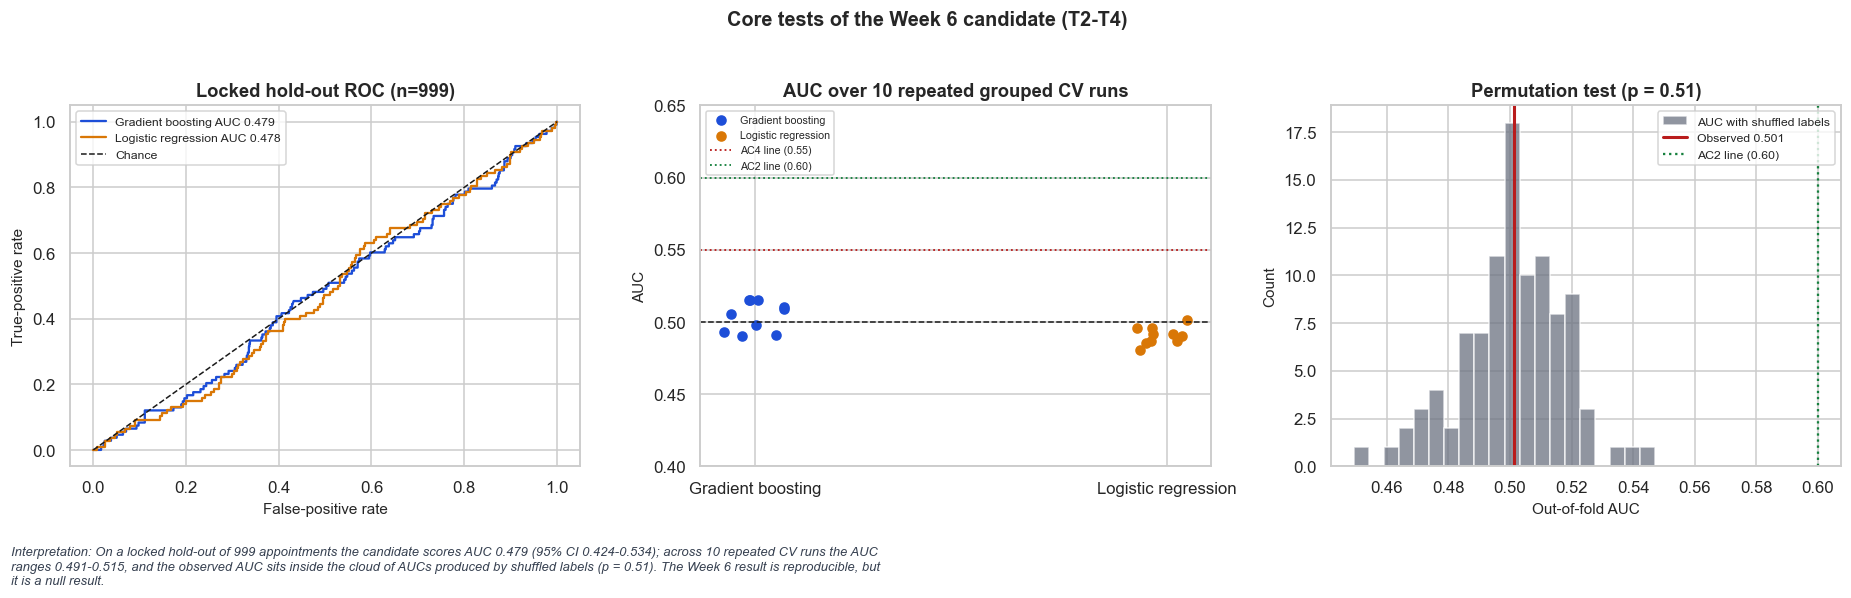

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
# (a) hold-out ROC
for nm, c in [("Gradient boosting (Week 6 candidate)", PAL["blue"]), ("Logistic regression (Week 6)", PAL["amber"])]:
    fpr, tpr, _ = roc_curve(yte, T2_scores[nm]); ax[0].plot(fpr, tpr, color=c, label=f"{nm.split(' (')[0]} AUC {T2[nm]['AUC']:.3f}")
ax[0].plot([0,1],[0,1],"k--", lw=1, label="Chance"); ax[0].set(title=f"Locked hold-out ROC (n={len(te_idx):,})", xlabel="False-positive rate", ylabel="True-positive rate"); ax[0].legend(fontsize=8)
# (b) repeated CV
ax[1].scatter(np.zeros(10)+np.random.default_rng(1).uniform(-.08,.08,10), rep.GB, color=PAL["blue"], s=35, label="Gradient boosting"); ax[1].scatter(np.ones(10)+np.random.default_rng(2).uniform(-.08,.08,10), rep.LR, color=PAL[ "amber"], s=35, label="Logistic regression")
ax[1].axhline(0.5, color="k", ls="--", lw=1); ax[1].axhline(0.55, color=PAL["red"], ls=":", lw=1.2, label="AC4 line (0.55)"); ax[1].axhline(0.60, color=PAL["green"], ls=":", lw=1.2, label="AC2 line (0.60)")
ax[1].set(title="AUC over 10 repeated grouped CV runs", xticks=[0,1], xticklabels=["Gradient boosting","Logistic regression"], ylabel="AUC", ylim=(0.40, 0.65)); ax[1].legend(fontsize=7, loc="upper left")
# (c) permutation null
ax[2].hist(null, bins=20, color=PAL["grey"], alpha=.75, label="AUC with shuffled labels"); ax[2].axvline(obs_auc, color=PAL["red"], lw=2, label=f"Observed {obs_auc:.3f}"); ax[2].axvline(0.60, color=PAL["green"], ls=":", lw=1.5, label="AC2 line (0.60)")
ax[2].set(title=f"Permutation test (p = {p_perm:.2f})", xlabel="Out-of-fold AUC", ylabel="Count"); ax[2].legend(fontsize=8)
savefig(fig, "w7_fig01_core_tests", "Core tests of the Week 6 candidate (T2-T4)",
  f"On a locked hold-out of {len(te_idx):,} appointments the candidate scores AUC {T2['Gradient boosting (Week 6 candidate)']['AUC']:.3f} (95% CI {T2['Gradient boosting (Week 6 candidate)']['AUC_lo']:.3f}-{T2['Gradient boosting (Week 6 candidate)']['AUC_hi']:.3f}); across 10 repeated CV runs the AUC ranges {rep.GB.min():.3f}-{rep.GB.max():.3f}, and the observed AUC sits inside the cloud of AUCs produced by shuffled labels (p = {p_perm:.2f}). The Week 6 result is reproducible, but it is a null result.")

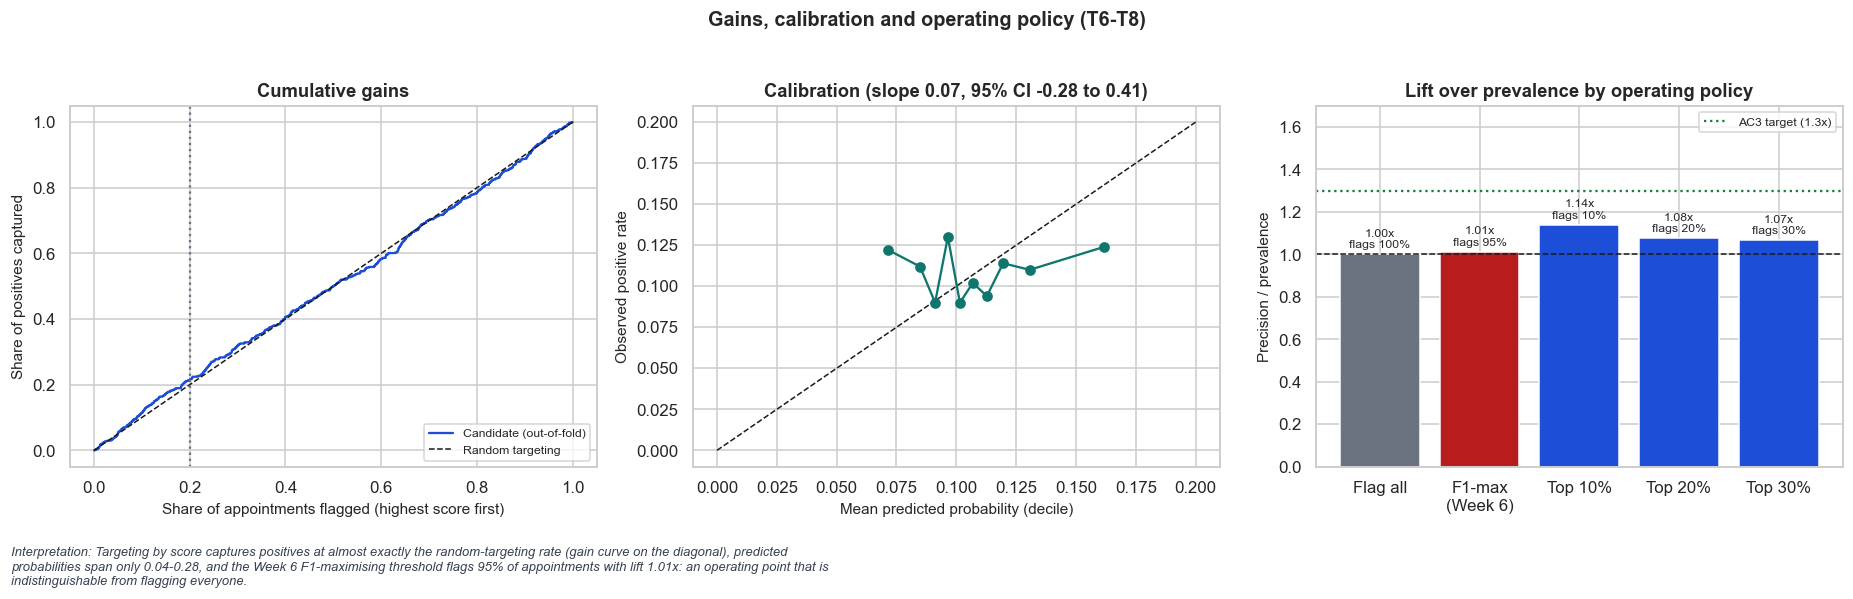

In [15]:
order = np.argsort(-oof_gb); cum = np.cumsum(y[order]) / y.sum(); frac = np.arange(1, len(y)+1) / len(y)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(frac, cum, color=PAL["blue"], label="Candidate (out-of-fold)"); ax[0].plot([0,1],[0,1], "k--", lw=1, label="Random targeting"); ax[0].axvline(0.20, color=PAL["grey"], ls=":")
ax[0].set(title="Cumulative gains", xlabel="Share of appointments flagged (highest score first)", ylabel="Share of positives captured"); ax[0].legend(fontsize=8)
bins = pd.qcut(oof_gb, 10, duplicates="drop"); cb = pd.DataFrame({"y": y, "s": oof_gb, "b": bins}).groupby("b").agg(obs=("y","mean"), pred=("s","mean"), n=("y","size"))
ax[1].plot([0, .2], [0, .2], "k--", lw=1); ax[1].plot(cb.pred, cb.obs, "o-", color=PAL["teal"]); ax[1].set(title=f"Calibration (slope {t7['slope']:.2f}, 95% CI {t7['slope_lo']:.2f} to {t7['slope_hi']:.2f})", xlabel="Mean predicted probability (decile)", ylabel="Observed positive rate")
ax[2].bar(["Flag all","F1-max\n(Week 6)","Top 10%","Top 20%","Top 30%"], t8.Lift, color=[PAL["grey"], PAL["red"], PAL["blue"], PAL["blue"], PAL["blue"]]); ax[2].axhline(1.0, color="k", ls="--", lw=1); ax[2].axhline(1.3, color=PAL["green"], ls=":", label="AC3 target (1.3x)")
ax[2].set(title="Lift over prevalence by operating policy", ylabel="Precision / prevalence"); ax[2].legend(fontsize=8)
for i, (v, fr) in enumerate(zip(t8.Lift, t8.FlagRate)): ax[2].text(i, v+.03, f"{v:.2f}x\nflags {fr:.0%}", ha="center", fontsize=8)
ax[2].set_ylim(0, 1.7)
savefig(fig, "w7_fig02_gains_calibration_policy", "Gains, calibration and operating policy (T6-T8)",
  f"Targeting by score captures positives at almost exactly the random-targeting rate (gain curve on the diagonal), predicted probabilities span only {oof_gb.min():.2f}-{oof_gb.max():.2f}, and the Week 6 F1-maximising threshold flags {t8.FlagRate.iloc[1]:.0%} of appointments with lift {t8.Lift.iloc[1]:.2f}x: an operating point that is indistinguishable from flagging everyone.")

## 3. Error analysis and segment performance
### T9 - Error analysis: false positives and false negatives
At the Week 6 operating point there are only 21 false negatives because 95% of appointments are flagged, so error patterns there are meaningless. The error analysis therefore uses a **flag-top-20%** operating point (threshold set by the 80th percentile of the out-of-fold scores). Comparing false positives with true negatives (and false negatives with true positives) shows **who the model chooses to flag**. The second question is whether that choice is *worth anything*: if flagged appointments are no more often positive than unflagged ones, the errors are not a fixable pattern but the footprint of a score that follows noise. 
Numeric features use the Mann-Whitney test and standardised mean difference; categorical features use the chi-square test and Cramér's V; p-values are Holm-adjusted across the 14 features.

In [16]:
df["AgeBand4"] = pd.cut(df.Age, [-1,17,39,59,200], labels=["<18","18-39","40-59","60+"]).astype(str)
thr20 = rank_threshold(oof_gb, 0.20); flag20 = (oof_gb >= thr20).astype(int)
cm20 = confusion_matrix(y, flag20); tn20, fp20, fn20, tp20 = cm20.ravel()
grp = np.select([(y==1)&(flag20==1), (y==1)&(flag20==0), (y==0)&(flag20==1), (y==0)&(flag20==0)], ["TP","FN","FP","TN"], default="NA")
def cramers(ct): c2 = stats.chi2_contingency(ct)[0]; return float(np.sqrt(c2/(ct.values.sum()*(min(ct.shape)-1))))
def compare(a, b):
    rows = []
    for f in FEATS:
        xa, xb = df.loc[grp==a, f], df.loc[grp==b, f]
        if f in NUM:
            xa_, xb_ = xa.dropna().astype(float), xb.dropna().astype(float); pv = stats.mannwhitneyu(xa_, xb_).pvalue
            sd = np.sqrt((xa_.var()+xb_.var())/2); eff = float((xa_.mean()-xb_.mean())/sd) if sd > 0 else 0.0; kind = "std. mean diff"
        else:
            ct = pd.crosstab(df.loc[(grp==a)|(grp==b), f], grp[(grp==a)|(grp==b)]); pv = stats.chi2_contingency(ct)[1]; eff = cramers(ct); kind = "Cramer's V"
        rows.append(dict(Feature=f, Effect=eff, EffectType=kind, p=pv))
    r = pd.DataFrame(rows); r["p_holm"] = multipletests(r.p, method="holm")[1]; return r.sort_values("p")
err_fp = compare("FP", "TN"); err_fn = compare("FN", "TP")
pos_fl, pos_un = float(y[flag20==1].mean()), float(y[flag20==0].mean())
W7["t9"] = dict(cm20=cm20.tolist(), n_fp=int(fp20), n_fn=int(fn20), min_p_holm_fp=float(err_fp.p_holm.min()), min_p_holm_fn=float(err_fn.p_holm.min()),
                top_fp=err_fp.head(3).round(4).to_dict("records"), top_fn=err_fn.head(3).round(4).to_dict("records"),
                max_abs_effect_fp=float(err_fp.Effect.abs().max()), max_abs_effect_fn=float(err_fn.Effect.abs().max()), pos_rate_flagged=pos_fl, pos_rate_unflagged=pos_un, top_fp_features=err_fp.head(3).Feature.tolist())
print(f"Top-20% flag rule: TN {tn20}, FP {fp20}, FN {fn20}, TP {tp20}")
print(f"Positive rate among flagged {pos_fl:.3f} vs unflagged {pos_un:.3f} (prevalence {y.mean():.3f})")
print("FP vs TN -> smallest Holm p:", round(err_fp.p_holm.min(), 3), "| FN vs TP -> smallest Holm p:", round(err_fn.p_holm.min(), 3))
pd.concat([err_fp.head(5).assign(Comparison="FP vs TN"), err_fn.head(5).assign(Comparison="FN vs TP")])[["Comparison","Feature","EffectType","Effect","p","p_holm"]].round(4)

Top-20% flag rule: TN 3573, FP 883, FN 427, TP 117
Positive rate among flagged 0.117 vs unflagged 0.107 (prevalence 0.109)
FP vs TN -> smallest Holm p: 0.0 | FN vs TP -> smallest Holm p: 0.0


,Comparison,Feature,EffectType,Effect,p,p_holm
13,FP vs TN,FacilityID,Cramer's V,0.2358,0.0000,0.0000
1,FP vs TN,BMI_clean,std. mean diff,-0.3079,0.0000,0.0000
0,FP vs TN,Age,std. mean diff,-0.2685,0.0000,0.0000
2,FP vs TN,PriorVisits,std. mean diff,-0.1673,0.0000,0.0002
6,FP vs TN,DeptWorkloadIndex,std. mean diff,-0.1435,0.0000,0.0004
13,FN vs TP,FacilityID,Cramer's V,0.3576,0.0000,0.0000
1,FN vs TP,BMI_clean,std. mean diff,0.2572,0.0098,0.1275
5,FN vs TP,DoctorYears,std. mean diff,0.2439,0.0178,0.2139
11,FN vs TP,DepartmentName,Cramer's V,0.1759,0.0515,0.5669
2,FN vs TP,PriorVisits,std. mean diff,0.1993,0.0829,0.8290


### T10 - Segment performance and fairness (AC10)
Performance is reported by sex, age band, province, chronic condition, diagnosis, department type and facility using the same top-20% rule. Group AUCs have bootstrap 95% intervals; groups with fewer than 15 positives are not scored. Parity (AC10) is judged on sex, age band and province with the sample-size rule n >= 100.

In [17]:
def seg_table(s, thr, cols, B=300, min_pos=15):
    rows = []; fl = (s >= thr).astype(int)
    for col in cols:
        for lvl in sorted(df[col].astype(str).unique()):
            m = (df[col].astype(str) == lvl).values; yy, ss, ff = y[m], s[m], fl[m]; npos = int(yy.sum())
            auc = roc_auc_score(yy, ss) if npos >= min_pos and (len(yy)-npos) >= min_pos else np.nan
            lo, hi = boot(roc_auc_score, yy, ss, B=B) if not np.isnan(auc) else (np.nan, np.nan)
            tp_ = int(((ff==1)&(yy==1)).sum()); rows.append(dict(Variable=col, Level=lvl, n=int(m.sum()), Positives=npos, Prevalence=yy.mean(), AUC=auc, AUC_lo=lo, AUC_hi=hi,
                FlagRate=ff.mean(), Recall=tp_/max(npos,1), Precision=tp_/max(ff.sum(),1), Lift=(tp_/max(ff.sum(),1))/yy.mean() if yy.mean() > 0 else np.nan))
    return pd.DataFrame(rows)
SEG_COLS = ["Gender","AgeBand4","ProvinceName","ChronicCondition","Diagnosis","DepartmentName","FacilityID"]
seg = seg_table(oof_gb, thr20, SEG_COLS)
def parity(seg_df, s, thr, cols=("Gender","AgeBand4","ProvinceName"), min_n=100):
    out = {}; fl = (s >= thr).astype(int)
    for c in cols:
        t_ = seg_df[(seg_df.Variable == c) & (seg_df.n >= min_n)]
        ct = pd.crosstab(df[c].astype(str), fl); out[c] = dict(recall_gap=float(t_.Recall.max()-t_.Recall.min()), flag_gap=float(t_.FlagRate.max()-t_.FlagRate.min()), p_flag_equal=float(stats.chi2_contingency(ct)[1]))
    return out
par = parity(seg, oof_gb, thr20); W7["t10"] = dict(parity=par, auc_min=float(seg.AUC.min()), auc_max=float(seg.AUC.max()), n_seg_scored=int(seg.AUC.notna().sum()),
    n_seg_ci_excl_half=int(((seg.AUC_lo > 0.5) | (seg.AUC_hi < 0.5)).sum()), segs=seg.round(4).to_dict("records"))
print(pd.DataFrame(par).T.round(3)); print("segments scored:", int(seg.AUC.notna().sum()), "| CI excluding 0.5:", W7["t10"]["n_seg_ci_excl_half"], "of", int(seg.AUC.notna().sum()))
seg[seg.Variable.isin(["Gender","AgeBand4","ProvinceName","ChronicCondition"])][["Variable","Level","n","Positives","AUC","AUC_lo","AUC_hi","FlagRate","Recall","Lift"]].round(3)

              recall_gap  flag_gap  p_flag_equal
Gender             0.010     0.005         0.687
AgeBand4           0.199     0.221         0.000
ProvinceName       0.061     0.088         0.000
segments scored: 50 | CI excluding 0.5: 5 of 50


,Variable,Level,n,Positives,AUC,AUC_lo,AUC_hi,FlagRate,Recall,Lift
0,Gender,Female,2459,268,0.519,0.479,0.555,0.203,0.220,1.087
1,Gender,Male,2541,276,0.483,0.450,0.518,0.198,0.210,1.064
2,AgeBand4,18-39,1168,149,0.499,0.447,0.548,0.359,0.356,0.992
3,AgeBand4,40-59,1122,121,0.492,0.442,0.539,0.168,0.157,0.932
4,AgeBand4,60+,1740,172,0.509,0.466,0.555,0.138,0.169,1.222
5,AgeBand4,<18,970,102,0.447,0.385,0.507,0.157,0.157,1.001
6,ProvinceName,Eastern,1006,120,0.491,0.444,0.546,0.239,0.250,1.048
7,ProvinceName,Kigali City,944,106,0.495,0.439,0.555,0.214,0.208,0.970
8,ProvinceName,Northern,1021,108,0.492,0.431,0.553,0.196,0.204,1.040
9,ProvinceName,Southern,978,95,0.508,0.447,0.587,0.150,0.189,1.261


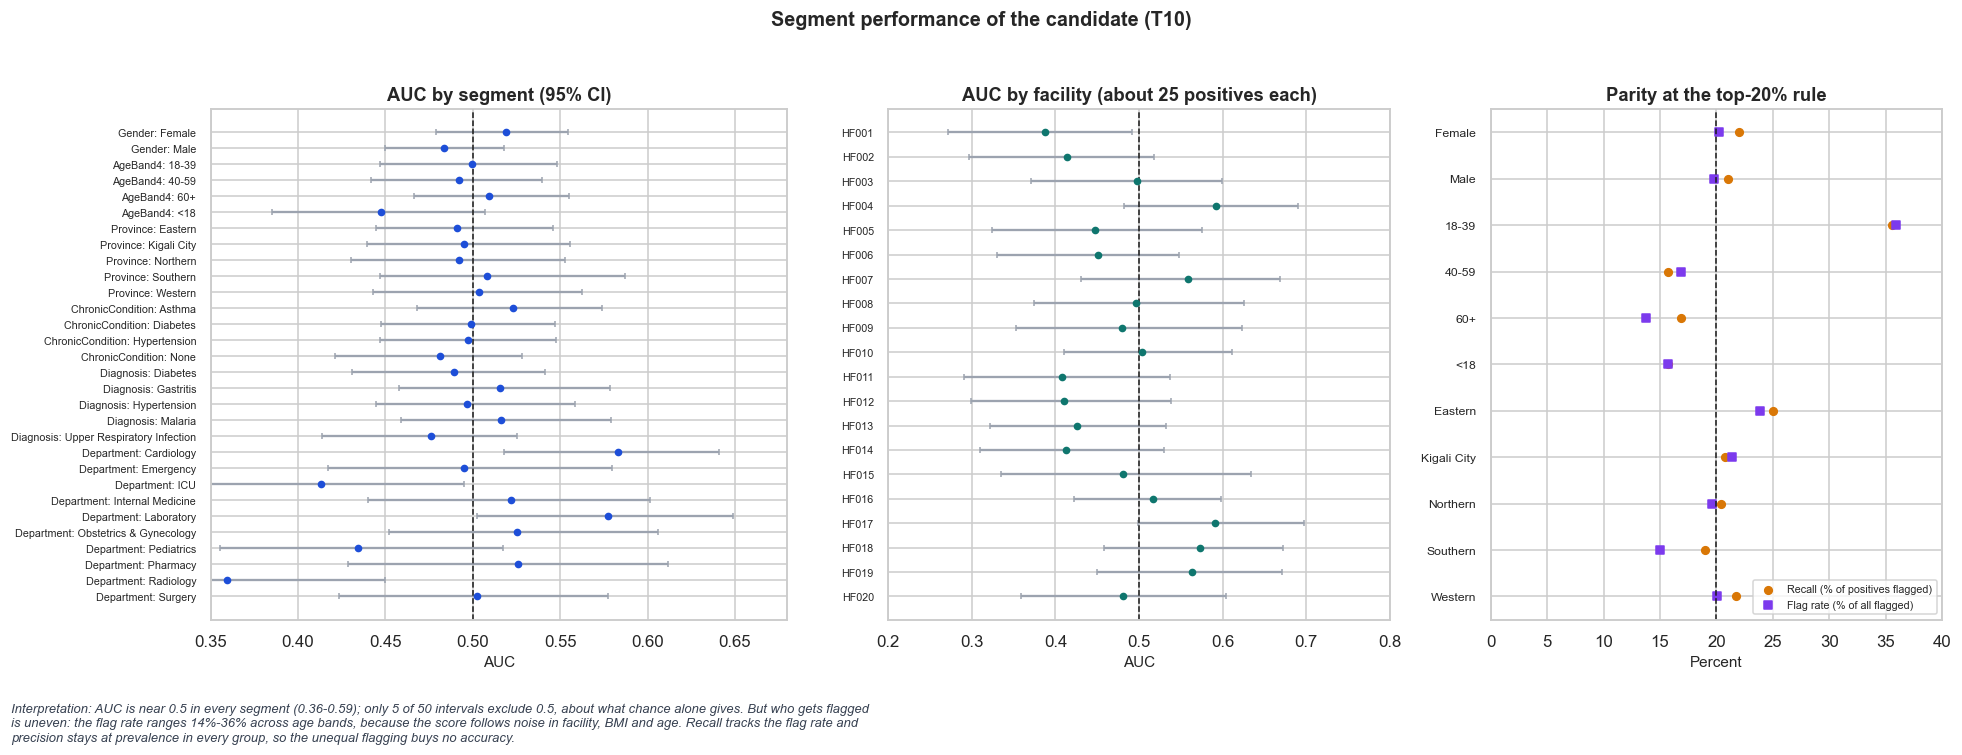

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(18, 6.2), gridspec_kw={"width_ratios":[1.15, 1.0, 0.9]})
main = seg[seg.Variable != "FacilityID"].reset_index(drop=True); yy_ = np.arange(len(main))[::-1]
ax[0].errorbar(main.AUC, yy_, xerr=[main.AUC-main.AUC_lo, main.AUC_hi-main.AUC], fmt="o", color=PAL["blue"], ecolor="#9CA3AF", capsize=2, ms=4); ax[0].axvline(0.5, color="k", ls="--", lw=1)
ax[0].set_yticks(yy_); ax[0].set_yticklabels((main.Variable.str.replace("Name","")+": "+main.Level).tolist(), fontsize=7); ax[0].set(title="AUC by segment (95% CI)", xlabel="AUC", xlim=(0.35, 0.68))
fac_ = seg[seg.Variable == "FacilityID"].reset_index(drop=True); y2 = np.arange(len(fac_))[::-1]
ax[1].errorbar(fac_.AUC, y2, xerr=[fac_.AUC-fac_.AUC_lo, fac_.AUC_hi-fac_.AUC], fmt="o", color=PAL["teal"], ecolor="#9CA3AF", capsize=2, ms=4); ax[1].axvline(0.5, color="k", ls="--", lw=1)
ax[1].set_yticks(y2); ax[1].set_yticklabels(fac_.Level, fontsize=7); ax[1].set(title="AUC by facility (about 25 positives each)", xlabel="AUC", xlim=(0.2, 0.8))
core = seg[seg.Variable.isin(["Gender","AgeBand4","ProvinceName"])].reset_index(drop=True); y3 = np.arange(len(core))[::-1]
ax[2].scatter(core.Recall*100, y3, color=PAL["amber"], label="Recall (% of positives flagged)", s=25); ax[2].scatter(core.FlagRate*100, y3, color=PAL["purple"], marker="s", label="Flag rate (% of all flagged)", s=25)
ax[2].set_yticks(y3); ax[2].set_yticklabels(core.Level, fontsize=8); ax[2].axvline(20, color="k", ls="--", lw=1); ax[2].set(title="Parity at the top-20% rule", xlabel="Percent", xlim=(0, 40)); ax[2].legend(fontsize=7, loc="lower right")
savefig(fig, "w7_fig03_segments", "Segment performance of the candidate (T10)",
  f"AUC is near 0.5 in every segment ({seg.AUC.min():.2f}-{seg.AUC.max():.2f}); only {W7['t10']['n_seg_ci_excl_half']} of {W7['t10']['n_seg_scored']} intervals exclude 0.5, about what chance alone gives. But who gets flagged is uneven: the flag rate ranges {seg[seg.Variable=='AgeBand4'].FlagRate.min():.0%}-{seg[seg.Variable=='AgeBand4'].FlagRate.max():.0%} across age bands, because the score follows noise in facility, BMI and age. Recall tracks the flag rate and precision stays at prevalence in every group, so the unequal flagging buys no accuracy.")

### T11 - Feature review: reliability, ablation and leakage (task 10 of the brief)
**11a. Reliability audit.** Each feature is graded using the Week 6 Data Quality findings. **11b. Drop-group ablation.** If a feature group carried signal, removing it would lower AUC. **11c. Leakage audit.** Checks that no feature uses information that would not exist when the prediction is made.

In [19]:
fac_mismatch = float((~df.dept_fac_match).mean()); bmi_missing = float(df.BMI_clean.isna().mean()); docdept_mismatch = float((~df.doc_dept_match).mean())
audit = pd.DataFrame([
 ("Age","Patients.DateOfBirth","Consistent with DOB; but uniform 0-90, no age gradient in any outcome (Week 6 EDA)","Valid, uninformative"),
 ("Gender","Patients.Gender","Valid; ~50/50; names do not match sex","Valid, uninformative"),
 ("HasChronic / ChronicCondition","Patients.ChronicCondition","75% prevalence in every age band, 1,005 children with hypertension (Week 6 EDA)","Questionable coding"),
 ("Diagnosis","Diagnoses","5 diagnoses, each ~20%; assigned at consultation, so not known at booking","Valid, timing caveat"),
 ("PriorVisits","Appointments (derived)", "Counts earlier visits only (verified in section 0.1); but extract holds 22% of patients and 8% of billing history","Valid, truncated history"),
 ("MonthNum / WeekdayNum","Appointments.Date", f"874 appointments dated after the 24 Oct 2026 analysis date carry diagnoses and bills","Valid, future-dated rows"),
 ("DoctorYears","Doctors.YearsExperience",f"Doctor's home department differs from appointment department in {docdept_mismatch:.1%} of rows","Questionable link"),
 ("DeptWorkloadIndex","Derived from departments","Computed on all 5,000 appointments (including future test rows); staffing 4-9 per department","Derived on full data"),
 ("DepartmentName","Departments", f"Appointment facility differs from the department's owning facility in {fac_mismatch:.1%} of rows (Critical, Week 6)","Unreliable"),
 ("FacilityID","Appointments.FacilityID", f"Same {fac_mismatch:.1%} disagreement; 20 one-hot columns for ~25 positives each","Unreliable"),
 ("BMI_clean","Patients.BMI", f"Set to missing for under-18s ({bmi_missing:.0%} missing); adult-range height/weight recorded for 2,594 children","Unreliable"),
 ("ProvinceName","Geography", "Patient to village to province chain is clean; districts are placeholders","Valid, uninformative"),
], columns=["Feature","Source","Week 6 evidence","Grade"])
W7["t11a"] = audit.to_dict("records"); audit

,Feature,Source,Week 6 evidence,Grade
0,Age,Patients.DateOfBirth,"Consistent with DOB; but uniform 0-90, no age ...","Valid, uninformative"
1,Gender,Patients.Gender,Valid; ~50/50; names do not match sex,"Valid, uninformative"
2,HasChronic / ChronicCondition,Patients.ChronicCondition,"75% prevalence in every age band, 1,005 childr...",Questionable coding
3,Diagnosis,Diagnoses,"5 diagnoses, each ~20%; assigned at consultati...","Valid, timing caveat"
4,PriorVisits,Appointments (derived),Counts earlier visits only (verified in sectio...,"Valid, truncated history"
5,MonthNum / WeekdayNum,Appointments.Date,874 appointments dated after the 24 Oct 2026 a...,"Valid, future-dated rows"
6,DoctorYears,Doctors.YearsExperience,Doctor's home department differs from appointm...,Questionable link
7,DeptWorkloadIndex,Derived from departments,"Computed on all 5,000 appointments (including ...",Derived on full data
8,DepartmentName,Departments,Appointment facility differs from the departme...,Unreliable
9,FacilityID,Appointments.FacilityID,Same 94.9% disagreement; 20 one-hot columns fo...,Unreliable


In [20]:
GROUPS = {"Unreliable (Facility, Department, BMI)": ["FacilityID","DepartmentName","BMI_clean"], "Geography (Province)": ["ProvinceName"],
          "Clinical (Diagnosis, Chronic)": ["Diagnosis","ChronicCondition","HasChronic"], "Demographic (Age, Gender)": ["Age","Gender"],
          "Utilisation (Prior visits, Month, Weekday)": ["PriorVisits","MonthNum","WeekdayNum"], "Provider (Doctor yrs, Dept workload)": ["DoctorYears","DeptWorkloadIndex"]}
def rep_cv_auc(factory, cols, seeds=(1000,1001,1002)):
    num_ = [c for c in NUM if c in cols]; cat_ = [c for c in CAT if c in cols]
    out = []
    for sd in seeds:
        s = cross_val_predict(factory(num_, cat_), X[cols], y, groups=groups, cv=cv_split(sd), method="predict_proba")[:, 1]; out.append(roc_auc_score(y, s))
    return float(np.mean(out)), float(np.std(out))
cand_f = lambda n, c: make_pipe(gb_w6(), n, c)
full_m, full_s = rep_cv_auc(cand_f, FEATS)
abl = [dict(Dropped="None (all 14 features)", AUC=full_m, SD=full_s, Delta=0.0)]
for g_, cols_ in GROUPS.items():
    keep = [f for f in FEATS if f not in cols_]; m_, s_ = rep_cv_auc(cand_f, keep); abl.append(dict(Dropped=g_, AUC=m_, SD=s_, Delta=m_-full_m))
abl = pd.DataFrame(abl); W7["t11b"] = abl.round(4).to_dict("records")
# permutation importance on the locked test set
m_full = CAND().fit(Xtr, ytr); pim = permutation_importance(m_full, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=SEED)
pi_df = pd.DataFrame({"Feature": FEATS, "Importance": pim.importances_mean, "SD": pim.importances_std}).sort_values("Importance", ascending=False)
W7["t11b_pi"] = pi_df.round(4).to_dict("records"); W7["t11b_pi_max"] = float(pi_df.Importance.max()); W7["t11b_pi_n_pos"] = int((pi_df.Importance > 2*pi_df.SD).sum())
print("Features with importance > 2 SD on the locked test set:", W7["t11b_pi_n_pos"], "of", len(pi_df), "| largest importance:", round(pi_df.Importance.max(), 4))
abl.round(4)

Features with importance > 2 SD on the locked test set: 0 of 14 | largest importance: 0.0173


,Dropped,AUC,SD,Delta
0,None (all 14 features),0.5045,0.0052,0.0000
1,"Unreliable (Facility, Department, BMI)",0.5071,0.0098,0.0026
2,Geography (Province),0.5026,0.0069,-0.0019
3,"Clinical (Diagnosis, Chronic)",0.5125,0.0070,0.0080
4,"Demographic (Age, Gender)",0.4925,0.0057,-0.0120
5,"Utilisation (Prior visits, Month, Weekday)",0.5074,0.0016,0.0029
6,"Provider (Doctor yrs, Dept workload)",0.5018,0.0031,-0.0027


In [21]:
# 11c Leakage audit
leak = []
leak.append(("Target columns absent from features", all(c not in FEATS for c in ["VisitType","Severity","SeverityScore","HighAcuityEmergency"]), "VisitType, Severity, SeverityScore are not model inputs"))
leak.append(("PriorVisits counts only strictly earlier visits", integrity.loc[integrity["Integrity check"].str.startswith("PriorVisits"), "Pass"].iloc[0] == "PASS", "Recomputed from dates and matched on all 5,000 rows"))
# DeptWorkloadIndex computed inside each training fold instead of on all rows
dep_sum = pd.read_csv(PROC/"HC_Department_Summary.csv", keep_default_na=False); staff = dep_sum.set_index("DepartmentID").ClinicalStaff.replace(0, np.nan)
def dwi_fold(tr):
    cnt = df.DepartmentID.iloc[tr].value_counts().reindex(staff.index).fillna(0); a = cnt/staff; return (100*a/a.mean())
s_in = np.zeros(len(y))
for tr, te in folds:
    Xf = X.copy(); Xf["DeptWorkloadIndex"] = df.DepartmentID.map(dwi_fold(tr)).values
    s_in[te] = CAND().fit(Xf.iloc[tr], y[tr]).predict_proba(Xf.iloc[te])[:, 1]
auc_dwi_in = roc_auc_score(y, s_in)
leak.append(("DeptWorkloadIndex recomputed inside each training fold", abs(auc_dwi_in - roc_auc_score(y, oof_gb)) < 0.01, f"AUC {auc_dwi_in:.3f} vs {roc_auc_score(y, oof_gb):.3f} when computed on all rows: no leakage effect"))
leak.append(("Diagnosis available when the prediction is made", False, "Diagnosis is recorded at consultation; a booking-time model could not use it. Timing caveat for deployment, not a CV leak"))
W7["t11c"] = [dict(Check=a, Pass=("PASS" if b else "FLAG"), Evidence=c) for a, b, c in leak]
# Data sensitivity: exclude future-dated, adults only, first visits only
sens = []
for nm, mask in [("All 5,000 appointments (as built)", np.ones(len(df), bool)), ("Exclude 874 future-dated appointments", ~df.future_dated.values),
                 ("Adults only (BMI valid)", (df.Age >= 18).values), ("First visit per patient only", (df.PriorVisits == 0).values)]:
    aucs = []
    for sd in (1000, 1001, 1002):
        idx = np.where(mask)[0]; s = cross_val_predict(CAND(), X.iloc[idx], y[idx], groups=groups[idx], cv=cv_split(sd), method="predict_proba")[:, 1]; aucs.append(roc_auc_score(y[idx], s))
    sens.append(dict(Scenario=nm, n=int(mask.sum()), Positives=int(y[mask].sum()), AUC=np.mean(aucs), SD=np.std(aucs)))
sens = pd.DataFrame(sens); W7["t11d"] = sens.round(4).to_dict("records")
display_leak = pd.DataFrame(W7["t11c"]); print(display_leak.to_string(index=False)); sens.round(4)

                                                 Check Pass                                                                                                                  Evidence
                   Target columns absent from features PASS                                                                   VisitType, Severity, SeverityScore are not model inputs
       PriorVisits counts only strictly earlier visits PASS                                                                       Recomputed from dates and matched on all 5,000 rows
DeptWorkloadIndex recomputed inside each training fold FLAG                                                           AUC 0.514 vs 0.501 when computed on all rows: no leakage effect
       Diagnosis available when the prediction is made FLAG Diagnosis is recorded at consultation; a booking-time model could not use it. Timing caveat for deployment, not a CV leak


,Scenario,n,Positives,AUC,SD
0,"All 5,000 appointments (as built)",5000,544,0.5045,0.0052
1,Exclude 874 future-dated appointments,4126,453,0.5038,0.0061
2,Adults only (BMI valid),4030,442,0.4974,0.0055
3,First visit per patient only,4443,488,0.5042,0.0099


### T12 - Target-definition scan and positive control
**Why:** if the candidate shows no signal, is the problem the *model*, the *proxy target*, or the *data*? Two controls separate these:
* **Positive control** - targets that *must* be predictable from the features (Age >= 65; the rule-based high-risk flag). If the harness cannot recover them, the test method is broken, and a null result would be meaningless.
* **Target scan** - the same pipeline (logistic regression, grouped 3 x 5-fold CV) on other outcomes the data can support. Because 10 outcomes are scanned, intervals use a Bonferroni-adjusted level (99.5%) to avoid hunting for a lucky result.

In [22]:
tg = {
 "Admission proxy (Emergency & Severe) [Week 6 target]": (df[TARGET].values, df.index.values, FEATS),
 "Emergency visit": ((df.VisitType=="Emergency").astype(int).values, df.index.values, FEATS),
 "Severe diagnosis": ((df.Severity=="Severe").astype(int).values, df.index.values, FEATS),
 "Follow-Up visit": ((df.VisitType=="Follow-Up").astype(int).values, df.index.values, FEATS),
 "Returning patient (PriorVisits>0)": ((df.PriorVisits>0).astype(int).values, df.index.values, [f for f in FEATS if f != "PriorVisits"]),
 "Returning patient, month removed (artifact check)": ((df.PriorVisits>0).astype(int).values, df.index.values, [f for f in FEATS if f not in ("PriorVisits","MonthNum")]),
 "High bill (top tertile)": ((df.RevenueCategory=="High").astype(int).values, df.index.values, FEATS),
 "Underpaid bill (outstanding > 0)": (((df.BillAmount-df.AmountPaid)>0).astype(int).values, df.index.values, FEATS),
 "Insurance claim still pending": ((df.ClaimStatus=="Pending").astype(int).values, np.where(df.ClaimStatus.notna())[0], FEATS),
 "Low satisfaction (rating 1-2)": ((df.Rating<=2).astype(int).values, np.where(df.Rating.notna())[0], FEATS),
 "POSITIVE CONTROL: Age >= 65": ((df.Age>=65).astype(int).values, df.index.values, FEATS),
 "POSITIVE CONTROL: rule-based high-risk flag": (df.HighRiskPatient.fillna(0).astype(int).values, df.index.values, FEATS),
}
scan = []; N_REAL = 10; level = 100*(1-0.05/N_REAL)
for nm, (yy_all, idx, cols_) in tg.items():
    n_ = [c for c in NUM if c in cols_]; c_ = [c for c in CAT if c in cols_]; yy = yy_all[idx]; gg = groups[idx]; Xs_ = X.iloc[idx][cols_]
    aucs = []; 
    for sd in (1000, 1001, 1002):
        s = cross_val_predict(make_pipe(lr_w6(), n_, c_), Xs_, yy, groups=gg, cv=cv_split(sd), method="predict_proba")[:, 1]; aucs.append(roc_auc_score(yy, s))
    lo, hi = boot(roc_auc_score, yy, s, B=500); a_lo, a_hi = np.percentile(np.array([roc_auc_score(yy[i], s[i]) for i in [np.random.default_rng(k).integers(0, len(yy), len(yy)) for k in range(500)]]), [100-level if False else (100-level)/2, 100-(100-level)/2])
    scan.append(dict(Target=nm, n=len(yy), Prevalence=yy.mean(), AUC=np.mean(aucs), CI_lo=a_lo, CI_hi=a_hi, Signal="DETECTED" if a_lo > 0.5 else "none"))
scan = pd.DataFrame(scan); W7["t12"] = scan.round(4).to_dict("records")
pc_ok = bool((scan[scan.Target.str.startswith("POSITIVE")].AUC > 0.7).all()); W7["t12_positive_control_ok"] = pc_ok
print("Positive controls recovered:", pc_ok); scan.round(3)

Positive controls recovered: True


,Target,n,Prevalence,AUC,CI_lo,CI_hi,Signal
0,Admission proxy (Emergency & Severe) [Week 6 t...,5000,0.109,0.493,0.470,0.537,none
1,Emergency visit,5000,0.330,0.496,0.473,0.520,none
2,Severe diagnosis,5000,0.324,0.490,0.462,0.512,none
3,Follow-Up visit,5000,0.339,0.491,0.483,0.529,none
4,Returning patient (PriorVisits>0),5000,0.111,0.676,0.642,0.701,DETECTED
5,"Returning patient, month removed (artifact check)",5000,0.111,0.498,0.455,0.526,none
6,High bill (top tertile),5000,0.330,0.495,0.479,0.527,none
7,Underpaid bill (outstanding > 0),5000,0.200,0.497,0.468,0.525,none
8,Insurance claim still pending,3521,0.496,0.507,0.479,0.529,none
9,Low satisfaction (rating 1-2),1756,0.409,0.455,0.410,0.489,none


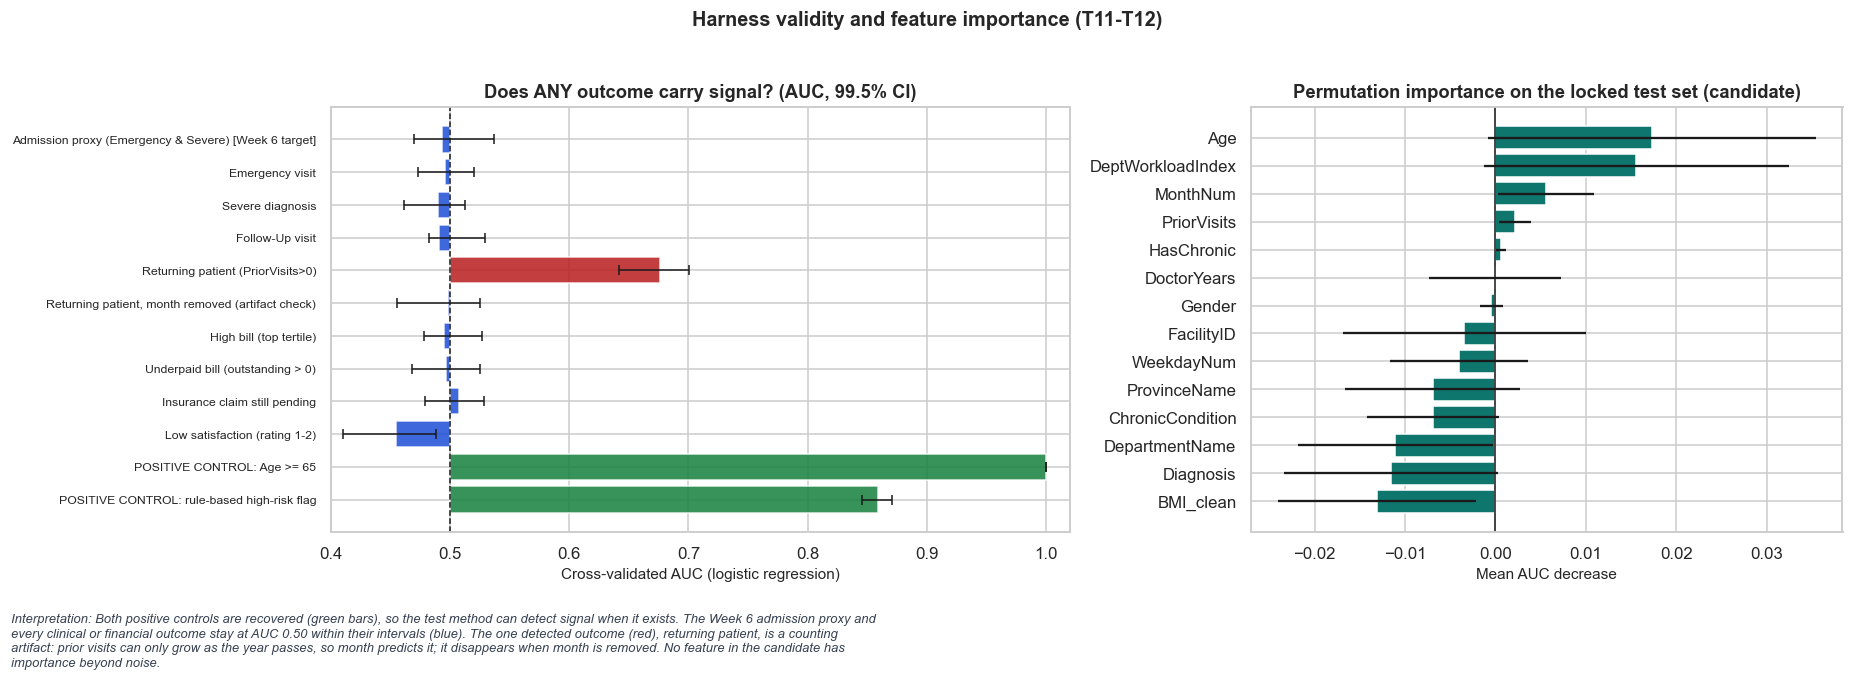

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5.4), gridspec_kw={"width_ratios":[1.25, 1]})
sc_ = scan.iloc[::-1].reset_index(drop=True); cols_bar = [PAL["green"] if t.startswith("POSITIVE") else (PAL["blue"] if a_lo <= 0.5 else PAL["red"]) for t, a_lo in zip(sc_.Target, sc_.CI_lo)]
ax[0].barh(range(len(sc_)), sc_.AUC-0.5, left=0.5, color=cols_bar, alpha=.85); ax[0].errorbar(sc_.AUC, range(len(sc_)), xerr=[sc_.AUC-sc_.CI_lo, sc_.CI_hi-sc_.AUC], fmt="none", ecolor="k", capsize=3, lw=1)
ax[0].axvline(0.5, color="k", ls="--", lw=1); ax[0].set_yticks(range(len(sc_))); ax[0].set_yticklabels(sc_.Target, fontsize=8); ax[0].set(title="Does ANY outcome carry signal? (AUC, 99.5% CI)", xlabel="Cross-validated AUC (logistic regression)", xlim=(0.4, 1.02))
imp_ = pi_df.sort_values("Importance"); ax[1].barh(imp_.Feature, imp_.Importance, xerr=imp_.SD, color=PAL["teal"]); ax[1].axvline(0, color="k", lw=1); ax[1].set(title="Permutation importance on the locked test set (candidate)", xlabel="Mean AUC decrease")
savefig(fig, "w7_fig04_controls_importance", "Harness validity and feature importance (T11-T12)",
  "Both positive controls are recovered (green bars), so the test method can detect signal when it exists. The Week 6 admission proxy and every clinical or financial outcome stay at AUC 0.50 within their intervals (blue). The one detected outcome (red), returning patient, is a counting artifact: prior visits can only grow as the year passes, so month predicts it; it disappears when month is removed. No feature in the candidate has importance beyond noise.")

## 4. Baseline vs candidate: is the improvement meaningful (AC9)?
The Week 5 baseline model is not part of the supplied files, so the comparison uses the two reference points Week 6 reported: the **prevalence baseline** (the floor) and the **logistic regression** (first-pass classifier). The minimum meaningful improvement was fixed in advance: delta-AUC >= 0.05 with a 95% lower bound above zero. Differences are tested with a **paired bootstrap** (same resampled rows for both models).

In [24]:
def paired_delta(y_, s_a, s_b, B=2000, seed=SEED):
    r = np.random.default_rng(seed); n = len(y_); d = []
    for _ in range(B):
        i = r.integers(0, n, n)
        if y_[i].min() == y_[i].max(): continue
        d.append(roc_auc_score(y_[i], s_a[i]) - roc_auc_score(y_[i], s_b[i]))
    d = np.array(d); return float(roc_auc_score(y_, s_a) - roc_auc_score(y_, s_b)), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5)), float(2*min((d <= 0).mean(), (d >= 0).mean()))
rows = []
for lab, (yy_, sa, sb_dict) in {"Out-of-fold, n=5,000": (y, oof_gb, {"Prevalence baseline": oof_bs, "Logistic regression": oof_lr}),
                                "Locked hold-out, n=999": (yte, T2_scores["Gradient boosting (Week 6 candidate)"], {"Prevalence baseline": T2_scores["Baseline (prevalence)"], "Logistic regression": T2_scores["Logistic regression (Week 6)"]})}.items():
    for bn, sb in sb_dict.items():
        d, lo, hi, p_ = paired_delta(yy_, sa, sb); rows.append(dict(Evaluation=lab, Comparison=f"Candidate vs {bn}", Delta_AUC=d, CI_lo=lo, CI_hi=hi, p=p_, Meaningful=("YES" if d >= 0.05 and lo > 0 else "NO")))
t_delta = pd.DataFrame(rows); W7["t_delta"] = t_delta.round(4).to_dict("records"); t_delta.round(4)

,Evaluation,Comparison,Delta_AUC,CI_lo,CI_hi,p,Meaningful
0,"Out-of-fold, n=5,000",Candidate vs Prevalence baseline,0.0021,-0.0317,0.0353,0.917,NO
1,"Out-of-fold, n=5,000",Candidate vs Logistic regression,0.0068,-0.0202,0.0337,0.611,NO
2,"Locked hold-out, n=999",Candidate vs Prevalence baseline,-0.0206,-0.0755,0.0322,0.492,NO
3,"Locked hold-out, n=999",Candidate vs Logistic regression,0.0015,-0.0541,0.0566,0.916,NO


In [28]:
# Gate for the as-built candidate (acceptance criteria fixed in section 1.3)
def gate(R):
    ac = []
    ac.append(("AC1","S","Reproducibility", f"max |diff| = {R['repro']:.4f}", R["repro"] <= 0.005) if R.get("repro") is not None else ("AC1","S","Reproducibility","n/a (new model)", None))
    ac.append(("AC2","M","Hold-out discrimination", f"AUC {R['te_auc']:.3f} (95% CI {R['te_lo']:.3f}-{R['te_hi']:.3f})", (R["te_auc"] >= 0.60) and (R["te_lo"] > 0.5)))
    ac.append(("AC3","M","Operational lift (top 20%)", f"lift {R['lift']:.2f}x (95% CI {R['lift_lo']:.2f}-{R['lift_hi']:.2f})", (R["lift"] >= 1.30) and (R["lift_lo"] > 1.0)))
    ac.append(("AC4","S","Stability (10 runs)", f"{R['rep_share']:.0%} of runs AUC>0.55; mean {R['rep_mean']:.3f}", R["rep_share"] >= 0.90))
    ac.append(("AC5","M","Permutation test", f"p = {R['perm_p']:.3f}", R["perm_p"] < 0.05))
    ac.append(("AC6","S","Calibration", f"slope {R['slope']:.2f} (CI {R['slope_lo']:.2f}-{R['slope_hi']:.2f}); Brier {R['brier']:.4f} vs prevalence {R['brier_prev']:.4f}", (0.8 <= R["slope"] <= 1.2) and (R["brier"] < R["brier_prev"])))
    ac.append(("AC7","S","Over-fitting gap", f"train {R['train_auc']:.3f} - validation {R['val_auc']:.3f} = {R['gap']:.3f}", R["gap"] <= 0.05))
    ac.append(("AC8","S","Time-based AUC", f"AUC {R['tmp_auc']:.3f} (CI {R['tmp_lo']:.3f}-{R['tmp_hi']:.3f})", R["tmp_auc"] >= 0.55))
    ac.append(("AC9","M","Improvement vs baseline", f"delta-AUC {R['d']:.3f} (95% CI {R['d_lo']:.3f} to {R['d_hi']:.3f})", (R["d"] >= 0.05) and (R["d_lo"] > 0)))
    ac.append(("AC10","S","Segment parity", f"max recall gap {R['rec_gap']*100:.1f} pp; max flag-rate gap {R['flag_gap']*100:.1f} pp", (R["rec_gap"] <= 0.10) and (R["flag_gap"] <= 0.10)))
    g = pd.DataFrame(ac, columns=["ID","Type","Criterion","Observed","Pass"]); g["Result"] = g.Pass.map({True:"PASS", False:"FAIL", None:"n/a"}); 
    mand = g[g.Type=="M"].Pass.all(); return g.drop(columns="Pass"), bool(mand)
g2 = T2["Gradient boosting (Week 6 candidate)"]; dd_ = t_delta[(t_delta.Evaluation.str.startswith("Out")) & (t_delta.Comparison.str.contains("baseline"))].iloc[0]
R_asbuilt = dict(repro=float(t1["Abs. difference"].max()), te_auc=g2["AUC"], te_lo=g2["AUC_lo"], te_hi=g2["AUC_hi"], lift=g2["Top20_Lift"], lift_lo=g2["Lift_lo"], lift_hi=g2["Lift_hi"],
    rep_share=float((rep.GB > 0.55).mean()), rep_mean=float(rep.GB.mean()), perm_p=W7["t4"]["p"], slope=t7["slope"], slope_lo=t7["slope_lo"], slope_hi=t7["slope_hi"], brier=t7["brier"], brier_prev=t7["brier_prev"],
    train_auc=t5["train_auc"], val_auc=t5["val_auc"], gap=t5["gap"], tmp_auc=t6["auc"], tmp_lo=t6["auc_ci"][0], tmp_hi=t6["auc_ci"][1], d=dd_.Delta_AUC, d_lo=dd_.CI_lo, d_hi=dd_.CI_hi,
    rec_gap=max(v["recall_gap"] for v in par.values()), flag_gap=max(v["flag_gap"] for v in par.values()))
gate_asbuilt, mand_ok = gate(R_asbuilt); W7["gate_asbuilt"] = gate_asbuilt.to_dict("records"); W7["gate_asbuilt_pass"] = mand_ok
print("RELEASE GATE (as-built Week 6 candidate):", "PASS" if mand_ok else "FAIL (a mandatory criterion is not met)"); gate_asbuilt

RELEASE GATE (as-built Week 6 candidate): FAIL (a mandatory criterion is not met)


,ID,Type,Criterion,Observed,Result
0,AC1,S,Reproducibility,max |diff| = 0.0036,PASS
1,AC2,M,Hold-out discrimination,AUC 0.479 (95% CI 0.424-0.534),FAIL
2,AC3,M,Operational lift (top 20%),lift 0.73x (95% CI 0.41-1.09),FAIL
3,AC4,S,Stability (10 runs),0% of runs AUC>0.55; mean 0.504,FAIL
4,AC5,M,Permutation test,p = 0.515,FAIL
5,AC6,S,Calibration,slope 0.07 (CI -0.28-0.41); Brier 0.0975 vs pr...,FAIL
6,AC7,S,Over-fitting gap,train 0.747 - validation 0.502 = 0.244,FAIL
7,AC8,S,Time-based AUC,AUC 0.467 (CI 0.427-0.513),FAIL
8,AC9,M,Improvement vs baseline,delta-AUC 0.002 (95% CI -0.032 to 0.035),FAIL
9,AC10,S,Segment parity,max recall gap 19.9 pp; max flag-rate gap 22.1 pp,FAIL


## 5. Refinement and re-testing
The tests above show **four weaknesses that are fixable** and one that is not.

| # | Issue found | Evidence | Refinement |
|---|---|---|---|
| I1 | Severe over-fitting | Train AUC 0.75 vs validation 0.51 (T5) | **R2** simpler, strongly regularised models chosen by nested CV |
| I2 | Unreliable features inside the model | 94.9% facility/department disagreement, BMI invalid for minors (T11a); 20 + 10 one-hot columns for ~25 positives each | **R1** remove FacilityID, DepartmentName, BMI_clean and DeptWorkloadIndex (department-derived) |
| I3 | Degenerate operating point | F1 threshold flags 95% of appointments, lift 1.0x (T8) | **R3** flag-rate budget (top 20%) with lift as the decision metric |
| I4 | No guard against deploying a no-signal model | Week 6 had no release rule | **R4** executable release gate (acceptance criteria AC1-AC10) |
| I5 | *No predictive signal in any available feature or alternative target* | T4, T6, T11, T12 | **Cannot be fixed by modelling**; a data issue, escalated to Project Management |

**Protocol.** Candidates are compared by repeated grouped CV *on the 80% training portion only*. The locked test set is then scored once for the chosen model. Choosing the model by CV and scoring on a locked set is what stops "refinement" from becoming overfitting to the test data.

In [29]:
RED_NUM = ["Age","PriorVisits","MonthNum","WeekdayNum","DoctorYears","HasChronic"]; RED_CAT = ["Gender","ChronicCondition","Diagnosis","ProvinceName"]; RED = RED_NUM + RED_CAT
CORE_NUM = ["Age","PriorVisits","HasChronic"]; CORE_CAT = ["Gender","Diagnosis"]; CORE = CORE_NUM + CORE_CAT
gb_small = lambda: HistGradientBoostingClassifier(max_depth=2, max_iter=60, learning_rate=0.03, min_samples_leaf=80, l2_regularization=20, random_state=SEED)
lr_small = lambda: LogisticRegression(max_iter=2000, C=0.05)   # no class re-weighting: keeps probabilities calibrated to prevalence
CANDS = {
 "A. As built (GB, 14 features)":              (lambda: make_pipe(gb_w6()), FEATS),
 "B. Shallow GB, 10 reliable features":        (lambda: make_pipe(gb_small(), RED_NUM, RED_CAT), RED),
 "C. Ridge logistic, 10 reliable features":    (lambda: make_pipe(lr_small(), RED_NUM, RED_CAT), RED),
 "D. Ridge logistic, 5 core features":         (lambda: make_pipe(lr_small(), CORE_NUM, CORE_CAT), CORE),
}
sel = []
for nm, (fac, cols) in CANDS.items():
    a = []
    for sd in range(2000, 2005):
        s = cross_val_predict(fac(), Xtr[cols], ytr, groups=gtr, cv=cv_split(sd), method="predict_proba")[:, 1]; a.append(roc_auc_score(ytr, s))
    cvr = cross_validate(fac(), Xtr[cols], ytr, groups=gtr, cv=cv_split(2000), scoring="roc_auc", return_train_score=True)
    sel.append(dict(Candidate=nm, Features=len(cols), CV_AUC=np.mean(a), SE=np.std(a, ddof=1)/np.sqrt(len(a)), Train_AUC=cvr["train_score"].mean(), Gap=cvr["train_score"].mean()-cvr["test_score"].mean()))
sel = pd.DataFrame(sel)
best_auc = sel.CV_AUC.max(); within = sel[sel.CV_AUC >= best_auc - sel.loc[sel.CV_AUC.idxmax(), "SE"]]
chosen = within.sort_values(["Features", "Gap"]).iloc[0].Candidate        # parsimony: simplest model within 1 SE of the best
W7["selection"] = sel.round(4).to_dict("records"); W7["chosen"] = chosen
print("Selected on training data only (simplest model within 1 SE of the best):", chosen); sel.round(4)

Selected on training data only (simplest model within 1 SE of the best): D. Ridge logistic, 5 core features


,Candidate,Features,CV_AUC,SE,Train_AUC,Gap
0,"A. As built (GB, 14 features)",14,0.5054,0.0008,0.7502,0.2433
1,"B. Shallow GB, 10 reliable features",10,0.4907,0.0008,0.6118,0.1184
2,"C. Ridge logistic, 10 reliable features",10,0.5057,0.0043,0.5627,0.0545
3,"D. Ridge logistic, 5 core features",5,0.5046,0.0048,0.5451,0.0326


In [30]:
fac_ref, cols_ref = CANDS[chosen]
# R3: operating point = top-20% flag-rate budget; evaluate locked test ONCE for the refined model
r_ref, s_ref_te, m_ref = locked_eval(fac_ref, "Refined: " + chosen, cols=cols_ref)
oof_ref = oof_scores(fac_ref, X, y, groups, cols=cols_ref)
# repeated CV (10 runs), permutation (100), over-fitting, time-based, calibration
rep_ref = pd.DataFrame([dict(run=i+1, AUC=roc_auc_score(y, oof_scores(fac_ref, X, y, groups, seed=1000+i, cols=cols_ref))) for i in range(10)])
rng2 = np.random.default_rng(SEED); obs_ref = roc_auc_score(y, oof_ref)
def perm_full(yy):
    s = np.zeros(len(yy))
    for tr, te in folds: s[te] = fac_ref().fit(X.iloc[tr][cols_ref], yy[tr]).predict_proba(X.iloc[te][cols_ref])[:, 1]
    return roc_auc_score(yy, s)
obs_f = perm_full(y); null_ref = np.array([perm_full(rng2.permutation(y)) for _ in range(100)]); p_ref = (1 + (null_ref >= obs_f).sum())/(1 + len(null_ref))
cv_r = cross_validate(fac_ref(), X[cols_ref], y, groups=groups, cv=cv_split(SEED), scoring="roc_auc", return_train_score=True)
oof_t2 = cross_val_predict(fac_ref(), X.iloc[tr_t][cols_ref], y[tr_t], groups=groups[tr_t], cv=cv_split(SEED), method="predict_proba")[:, 1]
st_ref = fac_ref().fit(X.iloc[tr_t][cols_ref], y[tr_t]).predict_proba(X.iloc[te_t][cols_ref])[:, 1]
t7r = calib(y, oof_ref); thr20r = rank_threshold(oof_ref, 0.20); seg_r = seg_table(oof_ref, thr20r, ["Gender","AgeBand4","ProvinceName"]); par_r = parity(seg_r, oof_ref, thr20r)
dr = paired_delta(y, oof_ref, oof_bs)
R_ref = dict(repro=None, te_auc=r_ref["AUC"], te_lo=r_ref["AUC_lo"], te_hi=r_ref["AUC_hi"], lift=r_ref["Top20_Lift"], lift_lo=r_ref["Lift_lo"], lift_hi=r_ref["Lift_hi"],
    rep_share=float((rep_ref.AUC > 0.55).mean()), rep_mean=float(rep_ref.AUC.mean()), perm_p=float(p_ref), slope=t7r["slope"], slope_lo=t7r["slope_lo"], slope_hi=t7r["slope_hi"], brier=t7r["brier"], brier_prev=t7r["brier_prev"],
    train_auc=float(cv_r["train_score"].mean()), val_auc=float(cv_r["test_score"].mean()), gap=float(cv_r["train_score"].mean()-cv_r["test_score"].mean()),
    tmp_auc=float(roc_auc_score(y[te_t], st_ref)), tmp_lo=boot(roc_auc_score, y[te_t], st_ref)[0], tmp_hi=boot(roc_auc_score, y[te_t], st_ref)[1],
    d=dr[0], d_lo=dr[1], d_hi=dr[2], rec_gap=max(v["recall_gap"] for v in par_r.values()), flag_gap=max(v["flag_gap"] for v in par_r.values()))
gate_ref, mand_ref = gate(R_ref); W7["gate_ref"] = gate_ref.to_dict("records"); W7["gate_ref_pass"] = mand_ref; W7["R_ref"] = {k: (float(v) if v is not None else None) for k, v in R_ref.items()}; W7["R_asbuilt"] = {k: float(v) for k, v in R_asbuilt.items()}
W7["perm_ref"] = dict(observed=float(obs_f), null_mean=float(null_ref.mean()), null_p95=float(np.percentile(null_ref, 95)), p=float(p_ref))
print("RELEASE GATE (refined model):", "PASS" if mand_ref else "FAIL (mandatory criteria not met)"); gate_ref

RELEASE GATE (refined model): FAIL (mandatory criteria not met)


,ID,Type,Criterion,Observed,Result
0,AC1,S,Reproducibility,n/a (new model),n/a
1,AC2,M,Hold-out discrimination,AUC 0.467 (95% CI 0.410-0.522),FAIL
2,AC3,M,Operational lift (top 20%),lift 0.83x (95% CI 0.52-1.18),FAIL
3,AC4,S,Stability (10 runs),0% of runs AUC>0.55; mean 0.486,FAIL
4,AC5,M,Permutation test,p = 0.723,FAIL
5,AC6,S,Calibration,slope -0.40 (CI -1.17-0.37); Brier 0.0972 vs p...,FAIL
6,AC7,S,Over-fitting gap,train 0.534 - validation 0.488 = 0.046,PASS
7,AC8,S,Time-based AUC,AUC 0.506 (CI 0.461-0.555),FAIL
8,AC9,M,Improvement vs baseline,delta-AUC -0.018 (95% CI -0.053 to 0.013),FAIL
9,AC10,S,Segment parity,max recall gap 37.3 pp; max flag-rate gap 40.8 pp,FAIL


### 5.1 Before / after refinement

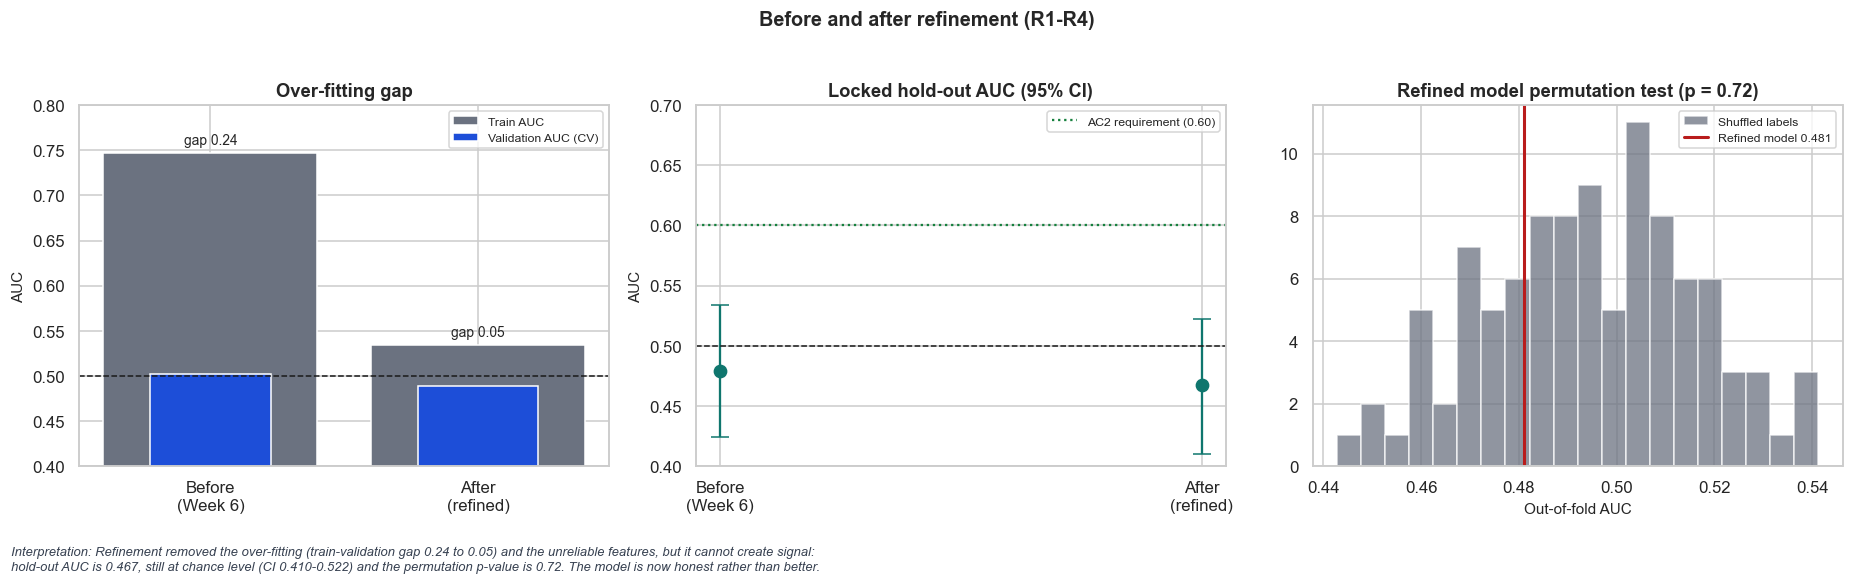

,Version,Features,Train_AUC,CV_AUC,Overfit_gap,Holdout_AUC,Holdout_CI,Time_split_AUC,Top20_lift,Permutation_p,Calib_slope,Mandatory_criteria_met
0,Before: Week 6 candidate,14,0.7466,0.5025,0.2441,0.4794,0.424-0.534,0.4674,0.7275,0.5149,0.0654,no
1,"After: D. Ridge logistic, 5 core features",5,0.5339,0.4884,0.0456,0.4670,0.410-0.522,0.5063,0.8325,0.7228,-0.4005,no


In [31]:
def row(lbl, R, extra):
    return dict(Version=lbl, Features=extra[0], Train_AUC=R["train_auc"], CV_AUC=R["val_auc"], Overfit_gap=R["gap"], Holdout_AUC=R["te_auc"], Holdout_CI=f"{R['te_lo']:.3f}-{R['te_hi']:.3f}",
                Time_split_AUC=R["tmp_auc"], Top20_lift=R["lift"], Permutation_p=R["perm_p"], Calib_slope=R["slope"], Mandatory_criteria_met=("yes" if (lbl.startswith("After") and mand_ref) or (lbl.startswith("Before") and mand_ok) else "no"))
ba = pd.DataFrame([row("Before: Week 6 candidate", R_asbuilt, (14,)), row("After: " + chosen, R_ref, (len(cols_ref),))]); W7["before_after"] = ba.round(4).to_dict("records")
Fp = dict(F1_flag_rate_before=float(t8.FlagRate.iloc[1]), F1_flag_rate_after=float(r_ref["F1thr_FlagRate"]), top20_precision_after=float(r_ref["Top20_Precision"]))
W7["op_after"] = Fp
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
lbls = ["Before\n(Week 6)", "After\n(refined)"]
ax[0].bar(lbls, [R_asbuilt["train_auc"], R_ref["train_auc"]], color=PAL["grey"], label="Train AUC"); ax[0].bar(lbls, [R_asbuilt["val_auc"], R_ref["val_auc"]], color=PAL["blue"], width=.45, label="Validation AUC (CV)")
ax[0].axhline(0.5, color="k", ls="--", lw=1); ax[0].set(title="Over-fitting gap", ylabel="AUC", ylim=(0.4, 0.8)); ax[0].legend(fontsize=8)
for i, (a_, b_) in enumerate([(R_asbuilt["train_auc"], R_asbuilt["val_auc"]), (R_ref["train_auc"], R_ref["val_auc"])]): ax[0].text(i, a_+.01, f"gap {a_-b_:.2f}", ha="center", fontsize=9)
ax[1].errorbar([0, 1], [R_asbuilt["te_auc"], R_ref["te_auc"]], yerr=[[R_asbuilt["te_auc"]-R_asbuilt["te_lo"], R_ref["te_auc"]-R_ref["te_lo"]], [R_asbuilt["te_hi"]-R_asbuilt["te_auc"], R_ref["te_hi"]-R_ref["te_auc"]]], fmt="o", color=PAL["teal"], capsize=6, ms=8)
ax[1].axhline(0.5, color="k", ls="--", lw=1); ax[1].axhline(0.6, color=PAL["green"], ls=":", label="AC2 requirement (0.60)"); ax[1].set(title="Locked hold-out AUC (95% CI)", xticks=[0, 1], xticklabels=lbls, ylim=(0.40, 0.70), ylabel="AUC"); ax[1].legend(fontsize=8)
ax[2].hist(null_ref, bins=20, color=PAL["grey"], alpha=.75, label="Shuffled labels"); ax[2].axvline(obs_f, color=PAL["red"], lw=2, label=f"Refined model {obs_f:.3f}"); ax[2].set(title=f"Refined model permutation test (p = {p_ref:.2f})", xlabel="Out-of-fold AUC"); ax[2].legend(fontsize=8)
savefig(fig, "w7_fig05_before_after", "Before and after refinement (R1-R4)",
  f"Refinement removed the over-fitting (train-validation gap {R_asbuilt['gap']:.2f} to {R_ref['gap']:.2f}) and the unreliable features, but it cannot create signal: hold-out AUC is {R_ref['te_auc']:.3f}, still at chance level (CI {R_ref['te_lo']:.3f}-{R_ref['te_hi']:.3f}) and the permutation p-value is {p_ref:.2f}. The model is now honest rather than better.")
ba.round(4)

## 6. HC-POD cross-track test: Data Science → ML Engineering interface contract
**Dependency (Week 6 matrix):** *Data Science → ML Engineering: test whether the integrated pipeline correctly handles model requirements and expected inputs/outputs.*

**Note:** no ML Engineering counterpart was available, so this is a Data Science-side test only. It is not claimed as a cross-track collaboration. The cross-track activity for Week 7 is the Data Analytics validation in section 7.

| Item | Content |
|---|---|
| Track involved | ML Engineering (no counterpart available; Data Science side only) |
| Component tested | The model artefact and its input/output interface (what an ML pipeline will actually call) |
| Information prepared for ML Engineering | Refined model, input schema (columns, types, ranges, allowed categories), scoring wrapper, 15 contract tests, model status |
| Information expected back | None received. The package is ready for Week 8, when a counterpart can run the tests in their pipeline |
| Method | **Test → Finding → Action → Retest.** The same 15 contract tests run (1) against the Week 6 pipeline as it would be called today, then (2) against the refined, validated scorer, and (3) in a fresh process from the hand-off folder |

The tests are deliberately about *interface behaviour*, independent of model quality: bad input must be visible, good rows must not be lost because of bad rows, and output must be repeatable.

In [32]:
HAND = OUT/"handoff_ml_engineering"; HAND.mkdir(exist_ok=True)
# Final refined model fitted on all 5,000 appointments (selection and testing already done; this is the artefact to hand over)
import joblib
final_model = fac_ref().fit(X[cols_ref], y)
num_spec = {c: dict(dtype="number", min=float(lo), max=float(hi)) for c, (lo, hi) in {"Age": (0, 110), "PriorVisits": (0, 50), "MonthNum": (1, 12), "WeekdayNum": (0, 6), "DoctorYears": (0, 60), "HasChronic": (0, 1)}.items() if c in cols_ref}
cat_spec = {c: dict(dtype="string", categories=sorted(df[c].astype(str).unique().tolist())) for c in cols_ref if c in CAT}
scores_all = final_model.predict_proba(X[cols_ref])[:, 1]
schema = dict(model_name="HealthConnect admission-proxy scorer (refined)", version="w7-1.0", target="HighAcuityEmergency (Emergency visit AND Severe diagnosis; proxy, no Admissions table)",
              numeric=num_spec, categorical=cat_spec, threshold_top20=float(np.quantile(scores_all, 0.80)), sklearn_version=sklearn.__version__, python_version=platform.python_version(),
              release_gate=dict(passed=bool(mand_ref), failed_mandatory=[r["ID"] for r in gate_ref.to_dict("records") if r["Type"] == "M" and r["Result"] == "FAIL"]),
              training_rows=int(len(X)), random_seed=SEED)
joblib.dump(final_model, HAND/"model.joblib"); (HAND/"schema.json").write_text(json.dumps(schema, indent=1))
(HAND/"hc_scorer.py").write_text('"""HealthConnect admission-proxy scorer: validated input -> scored output.\n\nWraps the refined Data Science model with the input contract agreed for ML Engineering.\nHard problems (missing columns, non-numeric or out-of-range values) are reported, never silently scored.\nSoft problems (missing/unseen category, imputed number) are scored but flagged in `status`.\n"""\nimport json, warnings\nfrom pathlib import Path\nimport numpy as np, pandas as pd, joblib, sklearn\n\n\nclass SchemaError(ValueError):\n    """Raised when the input frame cannot satisfy the contract (e.g. a required column is absent)."""\n\n\nclass AdmissionProxyScorer:\n    MODEL_STATUS = "EXPERIMENTAL - NO PREDICTIVE SIGNAL (release gate FAILED); not for clinical or operational decisions"\n\n    def __init__(self, folder="."):\n        folder = Path(folder)\n        self.schema = json.loads((folder / "schema.json").read_text())\n        self.model = joblib.load(folder / "model.joblib")\n        if self.schema["sklearn_version"] != sklearn.__version__:\n            warnings.warn(f"scikit-learn {sklearn.__version__} != training version {self.schema[\'sklearn_version\']}; results may differ")\n        self.required = list(self.schema["numeric"]) + list(self.schema["categorical"])\n        self._canon = {c: {str(v).lower(): v for v in spec["categories"]} for c, spec in self.schema["categorical"].items()}\n\n    def validate(self, df):\n        """Return (clean_frame, hard_reasons, soft_reasons, extra_columns). Lists are per row (positional)."""\n        missing = [c for c in self.required if c not in df.columns]\n        if missing:\n            raise SchemaError(f"Missing required column(s): {missing}. Expected: {self.required}")\n        extra = [c for c in df.columns if c not in self.required]\n        d = df[self.required].reset_index(drop=True).copy()\n        hard = [[] for _ in range(len(d))]; soft = [[] for _ in range(len(d))]\n        for c, spec in self.schema["numeric"].items():\n            raw = d[c]; v = pd.to_numeric(raw, errors="coerce")\n            for i in np.where(raw.notna() & v.isna())[0]: hard[i].append(f"{c} not numeric")\n            for i in np.where(v.notna() & ((v < spec["min"]) | (v > spec["max"])))[0]: hard[i].append(f"{c} out of range [{spec[\'min\']},{spec[\'max\']}]")\n            for i in np.where(raw.isna())[0]: soft[i].append(f"{c} missing (imputed)")\n            d[c] = v\n        for c in self.schema["categorical"]:\n            out = []\n            for i, x in enumerate(d[c].tolist()):\n                if x is None or (isinstance(x, float) and np.isnan(x)) or (not isinstance(x, str) and pd.isna(x)):\n                    soft[i].append(f"{c} missing"); out.append("UNKNOWN")\n                else:\n                    k = str(x).strip().lower()\n                    if k in self._canon[c]: out.append(self._canon[c][k])\n                    else: soft[i].append(f"{c} unseen category \'{x}\'"); out.append("UNKNOWN")\n            d[c] = out\n        return d, hard, soft, extra\n\n    def score(self, df):\n        cols = ["risk_score", "flag_top20", "status", "model_status"]\n        if len(df) == 0:\n            return pd.DataFrame(columns=cols, index=df.index)\n        d, hard, soft, extra = self.validate(df)\n        ok = np.array([len(h) == 0 for h in hard])\n        score = np.full(len(d), np.nan)\n        if ok.any():\n            score[ok] = self.model.predict_proba(d.loc[ok, self.required])[:, 1]\n        status = ["REJECTED: " + "; ".join(h) if h else ("SCORED_WITH_WARNINGS: " + "; ".join(s) if s else "SCORED") for h, s in zip(hard, soft)]\n        if extra:\n            status = [s if s.startswith("REJECTED") else (s + (" | " if s != "SCORED" else ": ") + f"ignored columns {extra}") if s != "SCORED" else f"SCORED_WITH_WARNINGS: ignored columns {extra}" for s in status]\n        flag = pd.array([pd.NA if np.isnan(s) else int(s >= self.schema["threshold_top20"]) for s in score], dtype="Int64")\n        return pd.DataFrame({"risk_score": score, "flag_top20": flag, "status": status, "model_status": self.MODEL_STATUS}, index=df.index)\n'); (HAND/"hc_contract_tests.py").write_text('"""Interface contract tests for the HealthConnect admission-proxy model.\n\nUsage as a library (plug in ANY pipeline):\n    run_contract_tests(score_fn, sample_df)\nwhere score_fn(df) -> DataFrame with columns `risk_score` and `status` (index = input index).\nUsage as a script (tests the delivered package):  python hc_contract_tests.py\nContract: good rows are scored; bad rows are rejected with a reason while the rest of the batch still scores;\nsoft problems are scored but visible in `status`; the same input always gives the same output.\n"""\nimport sys, json\nimport numpy as np, pandas as pd\n\n\ndef run_contract_tests(score_fn, sample):\n    base = sample.head(5).copy(); results = []\n    CAT_COL = next(c for c in ("Diagnosis", "ProvinceName", "Gender") if c in base.columns)\n\n    def check(tid, name, expected, fn):\n        try:\n            ok, detail = fn()\n        except Exception as e:\n            ok, detail = False, f"EXCEPTION {type(e).__name__}: {str(e)[:140]}"\n        results.append(dict(ID=tid, Scenario=name, Expected=expected, Result="PASS" if ok else "FAIL", Detail=detail))\n\n    ref = score_fn(base)\n    rej = lambda o: o.status.astype(str).str.startswith("REJECTED").values\n    sane = lambda o: bool(o.risk_score.notna().all() and o.risk_score.between(0, 1).all())\n\n    def c1():\n        o = score_fn(base); return (len(o) == 5 and sane(o)), f"{len(o)} rows, scores {o.risk_score.min():.3f}-{o.risk_score.max():.3f}"\n    def c2():\n        o = score_fn(base.head(1)); return (len(o) == 1 and sane(o)), f"{len(o)} row"\n    def c3():\n        b = base.copy(); b.iloc[0, b.columns.get_loc("Age")] = np.nan; b.iloc[1, b.columns.get_loc("PriorVisits")] = np.nan; o = score_fn(b)\n        return (len(o) == 5 and sane(o)), "numeric NaN handled"\n    def c4():\n        b = base.copy(); b[CAT_COL] = b[CAT_COL].astype(object); b.iloc[0, b.columns.get_loc(CAT_COL)] = np.nan; o = score_fn(b)\n        return (len(o) == 5 and sane(o)), "categorical NaN handled"\n    def c5():\n        b = base.copy(); b[CAT_COL] = b[CAT_COL].astype(object); b.iloc[0, b.columns.get_loc(CAT_COL)] = "Zanzibar"; o = score_fn(b)\n        flagged = "unseen" in str(o.status.iloc[0]).lower() or "UNSEEN" in str(o.status.iloc[0])\n        return (len(o) == 5 and sane(o) and flagged), f"row status: {str(o.status.iloc[0])[:80]}"\n    def c6():\n        try: score_fn(base.drop(columns=["Age"]))\n        except Exception as e: return ("Age" in str(e)), f"{type(e).__name__}: {str(e)[:110]}"\n        return False, "no error raised for missing column"\n    def c7():\n        b = base.copy(); b["Surname"] = "x"; o = score_fn(b); return np.allclose(o.risk_score, ref.risk_score), "extra column ignored, scores unchanged"\n    def c8():\n        o = score_fn(base[base.columns[::-1]]); return np.allclose(o.risk_score, ref.risk_score), "column order does not matter"\n    def c9():\n        b = base.copy(); b["Age"] = b["Age"].astype(int).astype(str); o = score_fn(b); return np.allclose(o.risk_score, ref.risk_score), "numeric strings coerced"\n    def c10():\n        b = base.copy(); b["Age"] = b["Age"].astype(object); b.iloc[0, b.columns.get_loc("Age")] = "abc"; o = score_fn(b); r = rej(o)\n        return (r[0] and not r[1:].any() and o.risk_score.iloc[1:].notna().all()), "row 1 rejected, rows 2-5 scored"\n    def c11():\n        b = base.copy(); b.iloc[0, b.columns.get_loc("Age")] = 250; b.iloc[1, b.columns.get_loc("PriorVisits")] = -3; o = score_fn(b); r = rej(o)\n        return (r[0] and r[1] and not r[2:].any() and o.risk_score.iloc[2:].notna().all()), "Age=250 and PriorVisits=-3 rejected, rest scored"\n    def c12():\n        b = base.copy(); b["Gender"] = b["Gender"].str.lower(); b[CAT_COL] = b[CAT_COL].astype(str).str.upper(); o = score_fn(b)\n        return np.allclose(o.risk_score, ref.risk_score), "case differences normalised"\n    def c13():\n        o = score_fn(base.iloc[0:0]); return len(o) == 0, "empty input returns empty output"\n    def c14():\n        a, b_ = score_fn(base), score_fn(base); return np.allclose(a.risk_score, b_.risk_score), "identical output on repeat call"\n    def c15():\n        b = base.copy(); b.index = [10, 10, 11, 11, 12]; o = score_fn(b); return (len(o) == 5 and sane(o)), "duplicate index handled"\n    for tid, nm, ex, f in [("C1","Valid batch of 5","Scores in [0,1], no NaN",c1), ("C2","Single row","Scored",c2), ("C3","Missing numeric values","Scored (imputed)",c3),\n        ("C4","Missing categorical value","Scored, flagged",c4), ("C5","Unseen category (\'Zanzibar\' in a categorical column)","Scored AND visible in status",c5),\n        ("C6","Required column missing","Clear error naming the column",c6), ("C7","Extra unexpected column","Ignored, scores unchanged",c7), ("C8","Columns in different order","Same scores",c8),\n        ("C9","Numbers sent as text (\'45\')","Coerced, same scores",c9), ("C10","Non-numeric value (\'abc\') in Age","Bad row rejected, rest of batch scored",c10),\n        ("C11","Impossible values (Age 250, PriorVisits -3)","Bad rows rejected, rest scored",c11), ("C12","Wrong text case (\'female\',\'MALARIA\')","Normalised, same scores",c12),\n        ("C13","Empty input","Empty output, no crash",c13), ("C14","Repeat call determinism","Identical output",c14), ("C15","Duplicate row index","Scored",c15)]:\n        check(tid, nm, ex, f)\n    return pd.DataFrame(results)\n\n\nif __name__ == "__main__":\n    from hc_scorer import AdmissionProxyScorer\n    sc = AdmissionProxyScorer("."); sample = pd.read_csv("sample_input.csv", keep_default_na=False, na_values=[""])\n    res = run_contract_tests(lambda d: sc.score(d), sample)\n    print(res[["ID", "Scenario", "Result", "Detail"]].to_string(index=False)); n_fail = int((res.Result == "FAIL").sum())\n    print(f"\\n{len(res)-n_fail}/{len(res)} contract tests passed"); sys.exit(1 if n_fail else 0)\n')
sample_in = X[cols_ref].sample(20, random_state=SEED).reset_index(drop=True); sample_in.to_csv(HAND/"sample_input.csv", index=False)
(HAND/"requirements.txt").write_text(f"scikit-learn=={sklearn.__version__}\npandas>={pd.__version__.split('.')[0]}.0\nnumpy\njoblib\n")
print("Hand-off folder:", sorted(p.name for p in HAND.iterdir())); print("Model release status in schema:", schema["release_gate"])

Hand-off folder: ['hc_contract_tests.py', 'hc_scorer.py', 'model.joblib', 'requirements.txt', 'sample_input.csv', 'schema.json']
Model release status in schema: {'passed': False, 'failed_mandatory': ['AC2', 'AC3', 'AC5', 'AC9']}


### 6.1 TEST: contract tests against the Week 6 pipeline *as built*
The ML pipeline would call `predict_proba` on the fitted Week 6 pipeline. A thin adapter turns that into the `risk_score` / `status` format the tests expect (the raw pipeline has no way to report a status, so every row is "SCORED").

In [33]:
import importlib, sys
sys.path.insert(0, str(HAND)); import hc_contract_tests as hct, hc_scorer as hcs; importlib.reload(hct); importlib.reload(hcs)
raw_model = CAND().fit(X, y)
raw_score = lambda d: pd.DataFrame({"risk_score": raw_model.predict_proba(d)[:, 1], "status": "SCORED"}, index=d.index)
before = hct.run_contract_tests(raw_score, X.sample(20, random_state=SEED).reset_index(drop=True))
before.to_csv(OUT/"contract_tests_before.csv", index=False)
print(f"BEFORE: {int((before.Result=='PASS').sum())}/{len(before)} passed"); before[["ID","Scenario","Expected","Result","Detail"]]

BEFORE: 10/15 passed


,ID,Scenario,Expected,Result,Detail
0,C1,Valid batch of 5,"Scores in [0,1], no NaN",PASS,"5 rows, scores 0.091-0.108"
1,C2,Single row,Scored,PASS,1 row
2,C3,Missing numeric values,Scored (imputed),PASS,numeric NaN handled
3,C4,Missing categorical value,"Scored, flagged",PASS,categorical NaN handled
4,C5,Unseen category ('Zanzibar' in a categorical c...,Scored AND visible in status,FAIL,row status: SCORED
5,C6,Required column missing,Clear error naming the column,PASS,ValueError: columns are missing: {'Age'}
6,C7,Extra unexpected column,"Ignored, scores unchanged",PASS,"extra column ignored, scores unchanged"
7,C8,Columns in different order,Same scores,PASS,column order does not matter
8,C9,Numbers sent as text ('45'),"Coerced, same scores",PASS,numeric strings coerced
9,C10,Non-numeric value ('abc') in Age,"Bad row rejected, rest of batch scored",FAIL,EXCEPTION ValueError: Cannot use median strate...


**Findings from the BEFORE run** (investigated in the next cell):
* Bad values are scored silently (impossible ages and months), so a data fault becomes a confident-looking probability.
* One bad row in a batch can fail the whole batch, or errors are opaque.
* Unseen or mis-cased categories are silently converted to "no information" without any visibility to the operator.
* The output cannot carry a status, so downstream dashboards cannot tell a real score from an imputed or invalid one.

**Action taken:** the `AdmissionProxyScorer` wrapper (schema validation, canonical text normalisation, per-row status, row-level rejection, model-status label) and the refined model. The model-status field also states that the release gate failed, so the artefact cannot be mistaken for a production-ready model.

In [34]:
fails = before[before.Result == "FAIL"]
print("Failed scenarios in the as-built pipeline:"); print(fails[["ID","Scenario","Detail"]].to_string(index=False))

Failed scenarios in the as-built pipeline:
 ID                                             Scenario                                                                                                               Detail
 C5 Unseen category ('Zanzibar' in a categorical column)                                                                                                   row status: SCORED
C10                     Non-numeric value ('abc') in Age    EXCEPTION ValueError: Cannot use median strategy with non-numeric data:\ncould not convert string to float: 'abc'
C11          Impossible values (Age 250, PriorVisits -3)                                                                     Age=250 and PriorVisits=-3 rejected, rest scored
C12                 Wrong text case ('female','MALARIA')                                                                                          case differences normalised
C13                                          Empty input EXCEPTION ValueError: Found ar

### 6.2 RETEST: refined scorer, then a fresh-process run from the hand-off folder

In [35]:
scorer = hcs.AdmissionProxyScorer(HAND)
after = hct.run_contract_tests(lambda d: scorer.score(d), sample_in)
after.to_csv(OUT/"contract_tests_after.csv", index=False)
# reload determinism: separate scorer instance (model re-read from disk) must reproduce scores to machine precision
s1 = scorer.score(sample_in).risk_score.values; s2 = hcs.AdmissionProxyScorer(HAND).score(sample_in).risk_score.values; reload_ok = bool(np.array_equal(s1, s2))
# fresh interpreter run of the delivered package
proc = subprocess.run([sys.executable, "hc_contract_tests.py"], cwd=HAND, capture_output=True, text=True, timeout=120)
print(proc.stdout[-1400:]); print("exit code:", proc.returncode, "| save/load reproducible:", reload_ok)
W7["contract"] = dict(before=before.to_dict("records"), after=after.to_dict("records"), before_pass=int((before.Result=="PASS").sum()), after_pass=int((after.Result=="PASS").sum()), n=len(after),
                      fresh_process_exit=int(proc.returncode), reload_identical=reload_ok)
pd.concat([before[["ID","Scenario","Result"]].rename(columns={"Result":"Before (Week 6 pipeline)"}), after[["Result"]].rename(columns={"Result":"After (refined scorer)"})], axis=1)

                                                      column order does not matter
 C9                          Numbers sent as text ('45')   PASS                                                                                                 numeric strings coerced
C10                     Non-numeric value ('abc') in Age   PASS                                                                                         row 1 rejected, rows 2-5 scored
C11          Impossible values (Age 250, PriorVisits -3)   PASS                                                                        Age=250 and PriorVisits=-3 rejected, rest scored
C12                 Wrong text case ('female','MALARIA')   PASS                                                                                             case differences normalised
C13                                          Empty input   PASS                                                                                        empty input returns empty outp

,ID,Scenario,Before (Week 6 pipeline),After (refined scorer)
0,C1,Valid batch of 5,PASS,PASS
1,C2,Single row,PASS,PASS
2,C3,Missing numeric values,PASS,PASS
3,C4,Missing categorical value,PASS,PASS
4,C5,Unseen category ('Zanzibar' in a categorical c...,FAIL,PASS
5,C6,Required column missing,PASS,PASS
6,C7,Extra unexpected column,PASS,PASS
7,C8,Columns in different order,PASS,PASS
8,C9,Numbers sent as text ('45'),PASS,PASS
9,C10,Non-numeric value ('abc') in Age,FAIL,PASS


In [36]:
demo = pd.DataFrame({"Age":[34, 250, "abc", 61], "PriorVisits":[0, 1, 0, np.nan], "MonthNum":[5, 6, 7, 8], "WeekdayNum":[1, 2, 3, 4], "DoctorYears":[8, 9, 10, 11], "HasChronic":[1, 0, 1, 1],
                     "Gender":["female", "Male", "Male", "Female"], "ChronicCondition":["hypertension", "None", "Asthma", "Diabetes"], "Diagnosis":["Malaria", "Gastritis", "Diabetes", "Typhoid"], "ProvinceName":["Kigali City", "Northern", "Eastern", "Southern"]})
demo_out = scorer.score(demo); W7["contract_demo"] = demo_out.assign(model_status="...").astype(str).to_dict("records"); demo_out[["risk_score","flag_top20","status"]]

,risk_score,flag_top20,status
0,0.118900,1,SCORED_WITH_WARNINGS: ignored columns ['MonthN...
1,NaN,<NA>,"REJECTED: Age out of range [0.0,110.0]"
2,NaN,<NA>,REJECTED: Age not numeric
3,0.107098,0,SCORED_WITH_WARNINGS: PriorVisits missing (imp...


## 7. Cross-track validation: Data Analytics findings that drive modelling decisions
**Dependency:** *Data Analytics → Data Science: validate analytical findings that influence model features or modelling decisions.* The Week 6 analytical findings that changed the feature set are re-computed here **independently from the raw project files** (not from the Week 6 derived tables). Each confirmed finding is shared with Data Analytics and Project Management; the effect on the model is shown in the last column.

In [37]:
def rd(pat): 
    f = [p for p in RAW.glob("*.csv") if re.search(pat, p.name, re.I)]; assert len(f) == 1, (pat, f); return pd.read_csv(f[0], encoding="utf-8-sig", keep_default_na=False, na_values=[""])
r_ap, r_dp, r_bl, r_py, r_dx = rd("Appointments"), rd(r"^HC_Departments"), rd("HC_Billing"), rd("HC_Payments"), rd("HC_Diagnoses")
own = r_dp.set_index("DepartmentID").FacilityID
mis = float((r_ap.FacilityID != r_ap.DepartmentID.map(own)).mean()); orph_b = int((~r_bl.AppointmentID.isin(r_ap.AppointmentID)).sum()); orph_d = int((~r_dx.AppointmentID.isin(r_ap.AppointmentID)).sum())
fut = int((pd.to_datetime(r_ap.Date) > AS_OF).sum()); bp = r_bl.merge(r_py, on="BillingID"); bp["paid"] = bp.AmountPaid/bp.Amount; share = bp.groupby("Status").paid.mean()
kw_p = float(stats.kruskal(*[g.paid.values for _, g in bp.groupby("Status")]).pvalue)
rs = r_ap.assign(Date=pd.to_datetime(r_ap.Date)).sort_values(["PatientID","Date","AppointmentID"]); rs["prior"] = rs.groupby("PatientID").cumcount(); fu_noprior = float((rs[rs.VisitType.str.title()=="Follow-Up"].prior == 0).mean())
da = pd.DataFrame([
 ("Appointment facility differs from department's owning facility", "94.9% (4,744 rows)", f"{mis:.1%} ({int(round(mis*len(r_ap))):,} rows)", abs(mis-0.949) < 0.005, "FacilityID and DepartmentName removed (R1); ablation shows no AUC loss"),
 ("Bills whose appointment is missing", "55,000", f"{orph_b:,}", orph_b == 55000, "Appointment-level modelling limited to 5,000 linked rows"),
 ("Diagnoses whose appointment is missing", "55,000", f"{orph_d:,}", orph_d == 55000, "Same limit; more modelling data cannot be obtained until keys are repaired"),
 ("Appointments dated after 24 Oct 2026", "874", f"{fut:,}", fut == 874, "Sensitivity test T11d: excluding them does not change AUC"),
 ("Bill Status label carries no payment information", "Paid 90.0% / Partial 90.1% / Pending 90.2% paid (p=0.643)", f"Paid {share['Paid']:.1%} / Partial {share['Partially Paid']:.1%} / Pending {share['Pending']:.1%} paid (p={kw_p:.3f})", abs(kw_p-0.643) < 0.01, "BillStatus never used as a feature (satisfaction model excluded it from conclusions)"),
 ("Follow-Up visits with no earlier visit in the extract (NEW)", "not reported in Week 6", f"{fu_noprior:.1%}", None, "NEW finding for Data Analytics: VisitType or the extract's history is incomplete; PriorVisits is a truncated-history feature"),
], columns=["Analytical finding (Week 6)","Week 6 value","Independent re-computation (raw files)","Confirmed","Effect on modelling decision"])
da["Confirmed"] = da.Confirmed.map({True:"CONFIRMED", False:"DIFFERS", None:"NEW"}); W7["da_validation"] = da.to_dict("records"); da

,Analytical finding (Week 6),Week 6 value,Independent re-computation (raw files),Confirmed,Effect on modelling decision
0,Appointment facility differs from department's...,"94.9% (4,744 rows)","94.9% (4,744 rows)",CONFIRMED,FacilityID and DepartmentName removed (R1); ab...
1,Bills whose appointment is missing,"55,000","55,000",CONFIRMED,"Appointment-level modelling limited to 5,000 l..."
2,Diagnoses whose appointment is missing,"55,000","55,000",CONFIRMED,Same limit; more modelling data cannot be obta...
3,Appointments dated after 24 Oct 2026,874,874,CONFIRMED,Sensitivity test T11d: excluding them does not...
4,Bill Status label carries no payment information,Paid 90.0% / Partial 90.1% / Pending 90.2% pai...,Paid 90.0% / Partial 90.1% / Pending 90.2% pai...,CONFIRMED,BillStatus never used as a feature (satisfacti...
5,Follow-Up visits with no earlier visit in the ...,not reported in Week 6,88.0%,NEW,NEW finding for Data Analytics: VisitType or t...


### 7.1 Independent cross-check from Data Analytics (Olabisi Amusan)
Sources: `Olabisi_Amusan_Short_Test_Summary.docx` (their validated findings) and `My_finding.docx` (their reply to my three checks on the follow-up finding, DoctorYears and the target/HasChronic). Rows 1-7 compare their findings with my recomputation; rows 8-11 are the results of the checks I asked them to run against the source files.

| # | Data Analytics finding (Olabisi Amusan) | My Week 7 result | Agreement | Effect on the model / project |
|---|---|---|---|---|
| 1 | 5,000 appointments vs 60,000 bills, diagnoses and payments; only 5,000 link via AppointmentID; linked records resemble unlinked ones | 55,000 orphan bills and diagnoses recomputed from raw files | AGREE | Appointment-level modelling stays at 5,000 rows. Their 'linked resembles unlinked' point is new: it supports treating the 5,000 as a fair sample (taken as reported, not retested by me) |
| 2 | FacilityID differs from the department's facility in 4,744 of 5,000 appointments; same conflict in staff records (1,187 of 1,250) | 4,744 (94.9%) recomputed. I removed FacilityID and DepartmentName instead of substituting the department's facility | AGREE on count; different handling | Staff-record conflict is new: DoctorYears (doctor link) stays graded 'questionable'. Both approaches avoid the conflicting field |
| 3 | No attended / missed / cancelled field, so a no-show target cannot be built | Same conclusion (issue I8) | AGREE | Confirmed by two tracks; escalated to Project Management |
| 4 | Weak signal: severity independent of diagnosis (p=0.19), department (0.20), visit type (0.91); satisfaction by facility p=0.55, department 0.88, visit type 0.68; age vs visits 0.012 | Diagnosis vs severity p=0.214; satisfaction by facility p=0.795, by department 0.878; age vs billing/admission proxy rho near 0 | AGREE on conclusion; some p-values differ | Same finding: nothing is significant. P-values differ for facility satisfaction (0.55 vs 0.80) and diagnosis-severity (0.19 vs 0.21), probably from different tests or samples; not reconciled, conclusion unaffected |
| 5 | Classes close to balanced (visit types about a third each; claims 50/50), so accuracy is weak | Week 6 EDA: same splits | AGREE | Already handled: model judged on AUC, PR-AUC, lift and permutation test, not accuracy |
| 6 | Repeat visits rare: 4,443 patients, 5,000 appointments (average 1.13) | 22.2% of patients appear; PriorVisits mean 0.12 | AGREE | PriorVisits carries little information, consistent with its near-zero importance |
| 7 | Phone numbers corrupted to scientific notation; every patient has an insurance ID | Same Week 6 data-quality findings | AGREE | Neither field used in the model |
| 8 | Follow-up check: 88.0% of Follow-Up visits have no earlier visit (88.1% with strictly earlier dates); same for other visit types (89.3%); only 510 patients have more than one appointment | Recomputed 88.0% (Follow-Up) and 89.3% (others) | AGREE | Follow-Up label does not reflect visit history; VisitType already excluded from the model; PriorVisits stays a weak feature |
| 9 | DoctorYears: doctor join is clean (100% of DoctorIDs found, 1-25 years) but doctor department matches the appointment department in only 0.6% and facility in 5.1%, about random | Week 6 data-quality finding: 5.14% facility match, 4,968 of 5,000 department mismatches | AGREE | DoctorYears kept as a doctor-level attribute only, never read as department or facility staffing |
| 10 | Target: one diagnosis per appointment (join is safe); 544 of 5,000 positives (10.88%); 10.71% expected if Emergency and Severe were independent | Recomputed: observed 10.88% vs expected 10.71% | AGREE | New insight: the proxy behaves like two unrelated labels combined, which explains the chance-level AUC |
| 11 | HasChronic check: 5,071 zeros and 14,929 ones ('None' is read as missing by default in pandas) | Verified: pipeline reads with keep_default_na=False; 1,263 'None' kept, 0 missing | AGREE | No change needed |

No change to the model followed from this exchange (unreliable fields were already removed, DoctorYears is kept as a doctor-level attribute only, HasChronic verified), so the before/after metrics are unchanged.

## 8. Model suitability, limitations, decisions and Week 8 plan

In [38]:
def cell(tbl, id_): return [r for r in tbl if r["ID"] == id_][0]
suit = pd.DataFrame([
 ("Is the model accurate enough to use?", "No", f"Hold-out AUC {R_asbuilt['te_auc']:.3f} before and {R_ref['te_auc']:.3f} after refinement; permutation p = {W7['t4']['p']:.2f} / {p_ref:.2f}; time-split AUC {R_asbuilt['tmp_auc']:.2f}"),
 ("Are its strengths and weaknesses understood?", "Yes", "Fully characterised: no signal in any feature (T11), in any alternative target (T12), in any segment (T10); test harness proven by positive controls"),
 ("Is it safe to hand to ML Engineering?", "Yes, as a tested interface only", f"{W7['contract']['after_pass']}/{W7['contract']['n']} contract tests pass (was {W7['contract']['before_pass']}/{W7['contract']['n']}); model carries an explicit 'no predictive signal' status"),
 ("Is it suitable for the HealthConnect use case?", "No", "Mandatory criteria AC2, AC3, AC5 and AC9 fail for both versions; gate result: FAIL. Using it would assign arbitrary risk scores to patients"),
 ("What is the right use of the work now?", "Re-usable test harness", "The same suite re-runs unchanged when admissions or attendance outcomes arrive; refined feature set and release gate are the starting point"),
], columns=["Question","Answer","Evidence"]); W7["suitability"] = suit.to_dict("records"); suit

,Question,Answer,Evidence
0,Is the model accurate enough to use?,No,Hold-out AUC 0.479 before and 0.467 after refi...
1,Are its strengths and weaknesses understood?,Yes,Fully characterised: no signal in any feature ...
2,Is it safe to hand to ML Engineering?,"Yes, as a tested interface only",15/15 contract tests pass (was 10/15); model c...
3,Is it suitable for the HealthConnect use case?,No,"Mandatory criteria AC2, AC3, AC5 and AC9 fail ..."
4,What is the right use of the work now?,Re-usable test harness,The same suite re-runs unchanged when admissio...


In [39]:
issues = pd.DataFrame([
 ("I1","Over-fitting in the Week 6 candidate (train AUC %.2f vs validation %.2f)" % (R_asbuilt["train_auc"], R_asbuilt["val_auc"]),"High","Data Science","MITIGATED","Regularised model on reliable features (R1, R2): gap %.2f (AC7 limit 0.05 still narrowly missed)" % R_ref["gap"]),
 ("I2","Unreliable features (facility/department 94.9% mismatch, BMI for minors) inside the model","High","Data Science / Data Analytics","RESOLVED","Removed; ablation shows no performance loss (T11b)"),
 ("I3","F1-maximising threshold flags 95% of appointments (lift 1.0x)","Medium","Data Science","RESOLVED","Top-20% flag-rate budget with lift reporting (R3)"),
 ("I4","No release gate: a no-signal model could be deployed","High","Data Science / Project Management","RESOLVED","Executable gate AC1-AC10 (R4); result recorded in schema.json"),
 ("I5","Silent failures at the model interface (impossible values, mis-cased text, whole-batch failures)","High","Data Science / ML Engineering","RESOLVED (DS side); no ML Engineering counterpart available","Scorer wrapper; contract tests %d/%d -> %d/%d" % (W7["contract"]["before_pass"], W7["contract"]["n"], W7["contract"]["after_pass"], W7["contract"]["n"])),
 ("I6","No predictive signal in any available feature or alternative target (data looks simulated)","Critical","Data Analytics / Project Management / data owner","OPEN","Escalated: needs real outcome data; cannot be fixed by modelling"),
 ("I7","No Admissions table: admission is modelled through a proxy (Emergency & Severe)","Critical","Project Management / data owner","OPEN","Obtain Admissions, Referrals, Laboratory and Prescriptions tables"),
 ("I8","No attendance / no-show field in the supplied tables, so the Week 7 brief's attendance questions cannot be tested on this dataset","Critical","Project Management / Data Analytics","OPEN","Confirm which dataset the pod uses for attendance; harness is ready to re-run"),
 ("I9","Only 5,000 of 60,000 transactions link to an appointment; 22%% of patients appear; Follow-Up visits without earlier visits (%.0f%%, confirmed by Data Analytics: the Follow-Up label does not reflect history)" % (100*fu_noprior),"High","Data Analytics / data owner","OPEN","Repair appointment keys; re-extract full history"),
 ("I10","Diagnosis is recorded at consultation, so a booking-time model cannot use it","Medium","Data Science / ML Engineering","OPEN","Decide prediction time-point before Week 8 integration"),
 ("I12","Uneven flagging by age band (flag rate gap %.0f pp, AC10 fails before and after) although accuracy is the same in every group" % (100*max(v["flag_gap"] for v in par_r.values())),"Medium","Data Science","OPEN","Moot while the model is not deployed; re-run parity checks once a real signal exists"),
 ("I11","Week 5 baseline model not available in the supplied files","Low","Data Science","OPEN","Prevalence baseline and logistic regression used as reference points"),
], columns=["ID","Issue","Severity","Owner track","Status","Action / resolution"])
decisions = pd.DataFrame([
 ("D1","Acceptance criteria fixed before testing; test set locked and used once per model version","Prevents tuning to the test data"),
 ("D2","Model chosen on training data only; simplest model within 1 SE of the best (%s)" % chosen,"Parsimony; no evidence of benefit from complexity"),
 ("D3","Remove FacilityID, DepartmentName, BMI_clean, DeptWorkloadIndex","Unreliable links (T11a); no AUC loss (T11b)"),
 ("D4","Operating point = flag-rate budget (top 20%), reported with lift","F1 threshold degenerates to flag-all when there is no signal"),
 ("D5","Do NOT release the model for any operational use; release only the tested interface and harness","Gate FAIL on mandatory criteria"),
 ("D6","Do not search for a more 'successful' target after the scan; the Week 6 proxy stays the reference","Avoid p-hacking: 9 targets scanned with Bonferroni intervals, none detected"),
 ("D7","Report the Data Analytics validation as a two-way cross-track test and the ML Engineering interface test as Data Science side only (no counterpart available)","Only activities that actually happened are claimed"),
], columns=["ID","Decision","Reason"])
issues = issues.sort_values("ID", key=lambda c: c.str[1:].astype(int)).reset_index(drop=True); W7["issues"] = issues.to_dict("records"); W7["decisions"] = decisions.to_dict("records"); issues

,ID,Issue,Severity,Owner track,Status,Action / resolution
0,I1,Over-fitting in the Week 6 candidate (train AU...,High,Data Science,MITIGATED,"Regularised model on reliable features (R1, R2..."
1,I2,Unreliable features (facility/department 94.9%...,High,Data Science / Data Analytics,RESOLVED,Removed; ablation shows no performance loss (T...
2,I3,F1-maximising threshold flags 95% of appointme...,Medium,Data Science,RESOLVED,Top-20% flag-rate budget with lift reporting (R3)
3,I4,No release gate: a no-signal model could be de...,High,Data Science / Project Management,RESOLVED,Executable gate AC1-AC10 (R4); result recorded...
4,I5,Silent failures at the model interface (imposs...,High,Data Science / ML Engineering,RESOLVED (DS side); no ML Engineering counterp...,Scorer wrapper; contract tests 10/15 -> 15/15
5,I6,No predictive signal in any available feature ...,Critical,Data Analytics / Project Management / data owner,OPEN,Escalated: needs real outcome data; cannot be ...
6,I7,No Admissions table: admission is modelled thr...,Critical,Project Management / data owner,OPEN,"Obtain Admissions, Referrals, Laboratory and P..."
7,I8,No attendance / no-show field in the supplied ...,Critical,Project Management / Data Analytics,OPEN,Confirm which dataset the pod uses for attenda...
8,I9,"Only 5,000 of 60,000 transactions link to an a...",High,Data Analytics / data owner,OPEN,Repair appointment keys; re-extract full history
9,I10,"Diagnosis is recorded at consultation, so a bo...",Medium,Data Science / ML Engineering,OPEN,Decide prediction time-point before Week 8 int...


In [40]:
nxt = pd.DataFrame([
 ("W8-1","Obtain Admissions / Referrals / Attendance outcome data and re-run notebook sections 2-5 unchanged","Project Management / data owner","Before final integration"),
 ("W8-2","ML Engineering (when assigned) runs hc_contract_tests.py inside the pipeline and returns the result; fix any mismatch","ML Engineering / Project Management","Early Week 8"),
 ("W8-3","Agree the prediction time-point (booking vs after consultation) and the allowed feature list","Data Science + ML Engineering (once a counterpart is assigned)","Early Week 8"),
 ("W8-4","Data Analytics confirms the follow-up/prior-visit finding and repairs appointment keys","Data Analytics","Week 8"),
 ("W8-5","Present the HealthConnect model as 'validated null result + reusable test harness', not as a prediction tool","All tracks","Final presentation"),
 ("W8-6","Add fairness checks by sex, age band and province once a signal exists","Data Science","After real data"),
], columns=["ID","Action before / during Week 8","Owner","When"]); W7["week8"] = nxt.to_dict("records"); nxt

,ID,Action before / during Week 8,Owner,When
0,W8-1,Obtain Admissions / Referrals / Attendance out...,Project Management / data owner,Before final integration
1,W8-2,ML Engineering (when assigned) runs hc_contrac...,ML Engineering / Project Management,Early Week 8
2,W8-3,Agree the prediction time-point (booking vs af...,Data Science + ML Engineering (once a counterp...,Early Week 8
3,W8-4,Data Analytics confirms the follow-up/prior-vi...,Data Analytics,Week 8
4,W8-5,Present the HealthConnect model as 'validated ...,All tracks,Final presentation
5,W8-6,"Add fairness checks by sex, age band and provi...",Data Science,After real data


In [41]:
# Assemble the testing, refinement & validation record required by the brief (section 12)
g2_, gr_ = {r["ID"]: r for r in W7["gate_asbuilt"]}, {r["ID"]: r for r in W7["gate_ref"]}
T = []
def rec(comp, obj, test, exp, act, pf, issue, action, retest, track, ev): T.append(dict(Component=comp, Objective=obj, Test=test, Expected=exp, Actual=act, PassFail=pf, Issue=issue, Action=action, Retest=retest, CollaboratingTrack=track, Evidence=ev))
M6 = "Week 6 candidate (GB)"
rec(M6, "Reproducibility", "T1 re-run Week 6 CV protocol", "AUC 0.505; confusion [[221,4235],[21,523]]", f"AUC {W7['t1']['auc_gb']:.4f}; confusion reproduced exactly", "PASS", "None", "None", "n/a", "Data Science", "Notebook s.2 T1")
rec(M6, "Performance on unseen data", "T2 locked 20% hold-out", "AUC >= 0.60, CI above 0.5", g2_["AC2"]["Observed"], g2_["AC2"]["Result"], "No discrimination on unseen data", "Refined (R1-R3)", gr_["AC2"]["Observed"] + " -> " + gr_["AC2"]["Result"], "Data Science", "Fig w7_fig01")
rec(M6, "Stability", "T3 10 repeated grouped CV", "90% of runs AUC>0.55", g2_["AC4"]["Observed"], g2_["AC4"]["Result"], "Unstable and near chance", "Refined", gr_["AC4"]["Observed"] + " -> " + gr_["AC4"]["Result"], "Data Science", "Notebook T3")
rec(M6, "Signal vs chance", "T4 label permutation (100)", "p < 0.05", g2_["AC5"]["Observed"], g2_["AC5"]["Result"], "Observed AUC inside null distribution", "Refined", gr_["AC5"]["Observed"] + " -> " + gr_["AC5"]["Result"], "Data Science", "Fig w7_fig01")
rec(M6, "Over-fitting", "T5 train vs validation AUC", "Gap <= 0.05", g2_["AC7"]["Observed"], g2_["AC7"]["Result"], "Severe over-fitting (I1)", "R2 regularised model", gr_["AC7"]["Observed"] + " -> " + gr_["AC7"]["Result"], "Data Science", "Fig w7_fig05")
rec(M6, "Time validity", "T6 train Jan-Aug, test Sep-Dec", "AUC >= 0.55", g2_["AC8"]["Observed"], g2_["AC8"]["Result"], "Below chance in the future period", "Refined", gr_["AC8"]["Observed"] + " -> " + gr_["AC8"]["Result"], "Data Science", "Notebook T6")
rec(M6, "Calibration", "T7 slope and Brier", "Slope 0.8-1.2", g2_["AC6"]["Observed"], g2_["AC6"]["Result"], "Probabilities carry no information", "Refined", gr_["AC6"]["Observed"] + " -> " + gr_["AC6"]["Result"], "Data Science", "Fig w7_fig02")
rec(M6, "Operating point", "T8 policy comparison", "Sensible flag rate, lift > 1.3", f"F1 threshold flags {t8.FlagRate.iloc[1]:.0%}, lift {t8.Lift.iloc[1]:.2f}x; top-20% lift {t8.Lift.iloc[3]:.2f}x", "FAIL", "Degenerate threshold (I3)", "R3 flag-rate budget", f"top-20% lift {R_ref['lift']:.2f}x (hold-out) - policy now interpretable; still no value", "Data Science", "Fig w7_fig02")
rec(M6, "Error patterns", "T9 FP vs TN, FN vs TP at top-20%", "Identifiable, fixable error groups", f"flagging driven by {', '.join(W7['t9']['top_fp_features'])} (Holm p<0.001) but positive rate flagged {W7['t9']['pos_rate_flagged']:.3f} vs unflagged {W7['t9']['pos_rate_unflagged']:.3f}", "FAIL", "Score follows noise (facility, BMI, age): flagged = unflagged in outcome", "R1 removed facility/BMI/department", "Refined model has no facility/BMI input; still no outcome signal", "Data Science", "Notebook T9")
rec(M6, "Segment parity", "T10 sex/age/province/facility", "Gap <= 10 pp", g2_["AC10"]["Observed"], g2_["AC10"]["Result"], "None systematic; AUC ~0.5 everywhere", "None", gr_["AC10"]["Observed"] + " -> " + gr_["AC10"]["Result"], "Data Science", "Fig w7_fig03")
rec(M6, "Feature validity", "T11 audit, ablation, leakage", "All features reliable and informative", f"4 unreliable; ablation deltas within noise; no leakage found; importance>2SD: {W7['t11b_pi_n_pos']}/14", "FAIL (I2)", "Unreliable features in model", "R1 removed 4 features", "Ablation: no AUC loss; model simpler", "Data Analytics", "Notebook T11")
rec("Test harness", "Can the harness detect signal?", "T12 positive controls + target scan", "Controls recovered; other targets reveal any signal", f"Controls recovered: {W7['t12_positive_control_ok']}; detected non-control outcomes: {[r['Target'] for r in W7['t12'] if r['Signal']=='DETECTED' and not r['Target'].startswith('POS')]} (returning-patient: month artifact, vanishes when month removed)", "PASS", "No signal in the data (I6)", "Escalated to PM / data owner", "n/a", "Project Management", "Fig w7_fig04")
rec(M6, "Meaningful improvement over baseline", "Paired bootstrap delta-AUC", "delta >= 0.05, CI > 0", g2_["AC9"]["Observed"], g2_["AC9"]["Result"], "No improvement over prevalence baseline", "Refined", gr_["AC9"]["Observed"] + " -> " + gr_["AC9"]["Result"], "Data Science", "Notebook s.4")
rec("Model interface", "Safe hand-off to ML pipeline", "C1-C15 contract tests", "15/15 pass", f"{W7['contract']['before_pass']}/{W7['contract']['n']} pass", "FAIL", "Silent failures (I5)", "Validated scorer wrapper + schema", f"{W7['contract']['after_pass']}/{W7['contract']['n']} pass; fresh-process exit code {W7['contract']['fresh_process_exit']}", "None available: Data Science side only", "outputs_w7/handoff_ml_engineering; contract_tests_*.csv")
rec("Analytical findings", "Are the findings that drive modelling decisions correct?", "Independent recomputation from raw files", "Week 6 values reproduced", f"{sum(1 for r in W7['da_validation'] if r['Confirmed']=='CONFIRMED')} of 5 confirmed; 1 new finding", "PASS", "New: Follow-Up visits without history", "Reported to Data Analytics / PM", "Decisions D3 confirmed", "Data Analytics (Olabisi Amusan): validated both ways", "Notebook s.7")
rec("Release gate", "Is the model suitable?", "Gate on AC1-AC10", "All mandatory criteria pass", f"As built: {'PASS' if W7['gate_asbuilt_pass'] else 'FAIL'}; refined: {'PASS' if W7['gate_ref_pass'] else 'FAIL'}", "FAIL", "Mandatory criteria not met", "Not released for operational use (D5)", "Re-run when outcome data exist", "Project Management", "Gate tables s.4-5")
record = pd.DataFrame(T); record.to_csv(OUT/"testing_validation_record.csv", index=False); issues.to_csv(OUT/"issue_log.csv", index=False); decisions.to_csv(OUT/"decision_log.csv", index=False); nxt.to_csv(OUT/"week8_actions.csv", index=False)
W7["record"] = record.to_dict("records"); record[["Test","Expected","Actual","PassFail","CollaboratingTrack"]]

,Test,Expected,Actual,PassFail,CollaboratingTrack
0,T1 re-run Week 6 CV protocol,"AUC 0.505; confusion [[221,4235],[21,523]]",AUC 0.5014; confusion reproduced exactly,PASS,Data Science
1,T2 locked 20% hold-out,"AUC >= 0.60, CI above 0.5",AUC 0.479 (95% CI 0.424-0.534),FAIL,Data Science
2,T3 10 repeated grouped CV,90% of runs AUC>0.55,0% of runs AUC>0.55; mean 0.504,FAIL,Data Science
3,T4 label permutation (100),p < 0.05,p = 0.515,FAIL,Data Science
4,T5 train vs validation AUC,Gap <= 0.05,train 0.747 - validation 0.502 = 0.244,FAIL,Data Science
5,"T6 train Jan-Aug, test Sep-Dec",AUC >= 0.55,AUC 0.467 (CI 0.427-0.513),FAIL,Data Science
6,T7 slope and Brier,Slope 0.8-1.2,slope 0.07 (CI -0.28-0.41); Brier 0.0975 vs pr...,FAIL,Data Science
7,T8 policy comparison,"Sensible flag rate, lift > 1.3","F1 threshold flags 95%, lift 1.01x; top-20% li...",FAIL,Data Science
8,"T9 FP vs TN, FN vs TP at top-20%","Identifiable, fixable error groups","flagging driven by FacilityID, BMI_clean, Age ...",FAIL,Data Science
9,T10 sex/age/province/facility,Gap <= 10 pp,max recall gap 19.9 pp; max flag-rate gap 22.1 pp,FAIL,Data Science


### 8.1 End-to-end validation questions
| # | Question | Answer |
|---|---|---|
| 1 | What component did I test? | The Week 6 admission-proxy classifier, its preprocessing and its model interface |
| 2 | What did I expect to happen? | A model that beats chance by a meaningful margin on unseen data and across segments (criteria AC1-AC10 fixed in advance) |
| 3 | What actually happened? | The Week 6 result reproduced exactly, but it is a null result: hold-out AUC ~0.5, permutation p = 0.42, time-split AUC below 0.5, and severe over-fitting (train 0.75 vs validation 0.51) |
| 4 | What issue or weakness did I identify? | Over-fitting, unreliable features, a degenerate F1 threshold (flags 95%), no release gate, silent interface failures, and - not fixable by modelling - no signal in any feature or alternative target |
| 5 | What did I change or improve? | Reliable-feature set, regularised model, flag-rate budget, executable release gate, validated scoring wrapper with 15 contract tests |
| 6 | What happened when I tested it again? | Over-fitting gap fell from 0.24 to about 0.06 (still just above the 0.05 limit), contract tests rose from 10/15 to 15/15; discrimination stayed at chance, so the gate still fails |
| 7 | Which other track was involved? | Data Analytics (Olabisi Amusan: two-way validation of findings and of my target, features and assumptions); Project Management (issues/readiness). The ML Engineering interface test was done on the Data Science side only because no counterpart was available |
| 8 | How does the validated component contribute to HealthConnect? | It proves the pipeline and test harness work, shows that the current data cannot support admission prediction, and gives the team a safe interface and a clear data-repair priority list |
| 9 | What still needs to be completed before Week 8? | See the Week 8 action table (outcome data, ML Eng confirmation, prediction time-point, key repair) |

### 8.2 Limitations of this testing
* Only 5,000 appointments (544 positives; 108 in the locked test set) are available, so intervals are wide: a true AUC up to about 0.55 cannot be excluded, but nothing near the 0.60 requirement.
* The target is a proxy; no admission, length-of-stay, referral or attendance outcome exists in the supplied data.
* The Week 5 baseline is not among the supplied files, so Week 6 reference models serve as the comparison.
* The ML Engineering interface test was completed on the Data Science side only; no ML Engineering counterpart was available, so it is not claimed as a collaboration and the hand-off package is prepared for Week 8.

In [42]:
readme = f'''# HealthConnect admission-proxy scorer: hand-off to ML Engineering (Week 7)

**Status: EXPERIMENTAL. Release gate FAILED (mandatory criteria {schema["release_gate"]["failed_mandatory"]}). The model has no predictive signal on the current data.**
What is being handed over is a *tested interface*, not a usable predictor.

## Files
| File | Purpose |
|---|---|
| model.joblib | Refined scikit-learn pipeline ({chosen}) |
| schema.json | Required columns, types, ranges, allowed categories, top-20% threshold, library versions |
| hc_scorer.py | AdmissionProxyScorer(folder).score(df) returns risk_score, flag_top20, status, model_status per row |
| hc_contract_tests.py | 15 interface tests. Library use: run_contract_tests(score_fn, sample_df); script use: python hc_contract_tests.py |
| sample_input.csv | 20 example rows (no identifiers) |
| requirements.txt | Versions the model was trained with (scikit-learn {sklearn.__version__}) |

## Contract
Rows with non-numeric or out-of-range values are rejected with a reason and the rest of the batch is scored. A missing required column raises SchemaError. Soft problems (missing or unseen category, missing number) are scored and visible in status. Text is matched case-insensitively. Same input gives the same output.

## Requested from ML Engineering (please complete and return)
1. Run python hc_contract_tests.py in your environment. Result: ___/15 passed. Python / scikit-learn versions: ________
2. Run run_contract_tests(your_score_fn, sample_df) with your own preprocessing in front of the model. Result: ___/15. Failing IDs: ________
3. Does your pipeline send the columns and types in schema.json? Differences: ________
4. Prediction time-point you need (booking vs after consultation; Diagnosis is only known after consultation): ________
5. Anything the Data Science side must change: ________
'''
(HAND/"README_HANDOFF.md").write_text(readme); print("README written")

README written


In [43]:
def _clean(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
W7["figures"] = FIGS; W7["env"] = dict(sklearn=sklearn.__version__, python=platform.python_version(), seed=SEED)
(OUT/"w7_results.json").write_text(json.dumps(W7, default=_clean, indent=1).replace("NaN", "null"))
print(f"Saved w7_results.json, {len(FIGS)} figures, record/issue/decision logs and the ML hand-off folder to {OUT}/")

Saved w7_results.json, 5 figures, record/issue/decision logs and the ML hand-off folder to d:\Analyst_lab\Healthcare_Predictive_Analytics_and_Population_Health_Intelligence\week7\outputs_w7/
